# Insurance Prediction

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn import metrics
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score
%matplotlib inline

import warnings
warnings.filterwarnings("ignore")

In [ ]:
df = pd.read_csv('/content/insurance.csv')

In [ ]:
df.head(10)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
5,31,female,25.740,0,no,southeast,3756.62160
6,46,female,33.440,1,no,southeast,8240.58960
7,37,female,27.740,3,no,northwest,7281.50560
8,37,male,29.830,2,no,northeast,6406.41070
9,60,female,25.840,0,no,northwest,28923.13692


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [ ]:
df.shape

(1338, 7)

In [ ]:
df.isnull().sum().sort_values(ascending=False)

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


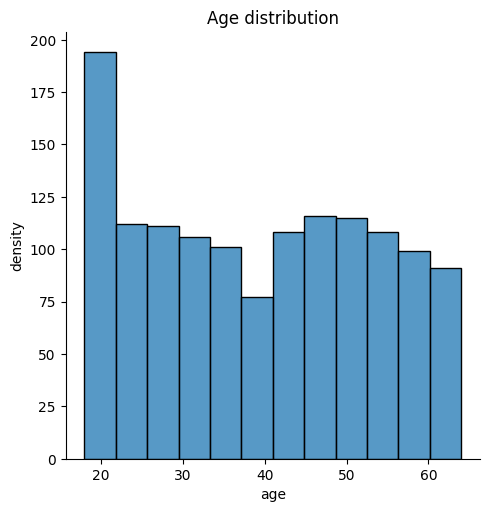

In [ ]:

sns.displot(df['age'])
plt.title('Age distribution')
plt.ylabel('density')
plt.xlabel('age')
plt.show()

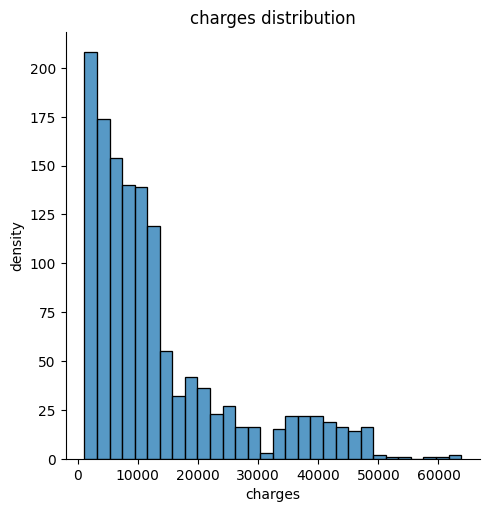

In [ ]:
sns.displot(df['charges'])
plt.title('charges distribution')
plt.ylabel('density')
plt.xlabel('charges')
plt.show()

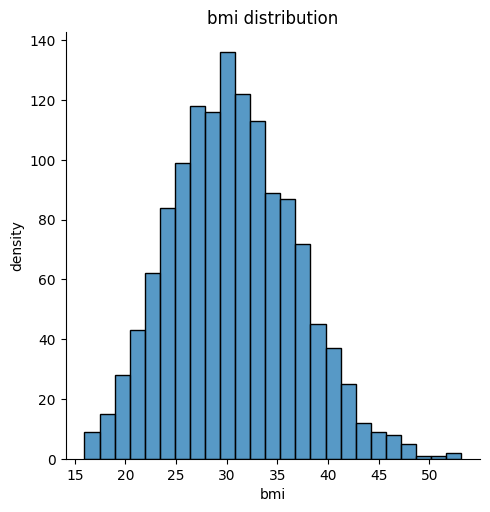

In [ ]:

sns.displot(df['bmi'])
plt.title('bmi distribution')
plt.ylabel('density')
plt.xlabel('bmi')
plt.show()

In [ ]:
df['region'].value_counts()

,count
region,
southeast,364
southwest,325
northwest,325
northeast,324


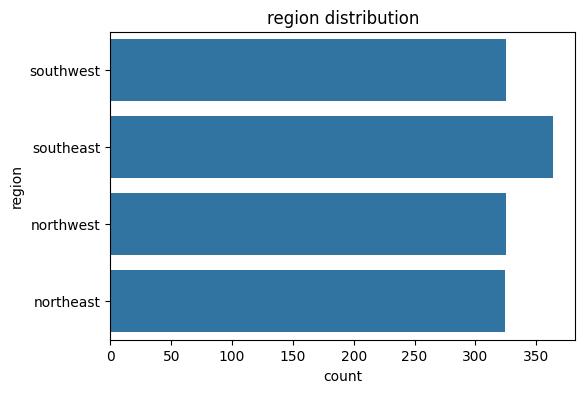

In [ ]:

fig = plt.figure(figsize=(6, 4))
sns.countplot(df['region'])
plt.title('region distribution')
plt.show()


In [ ]:

df['sex'].value_counts()


,count
sex,
male,676
female,662


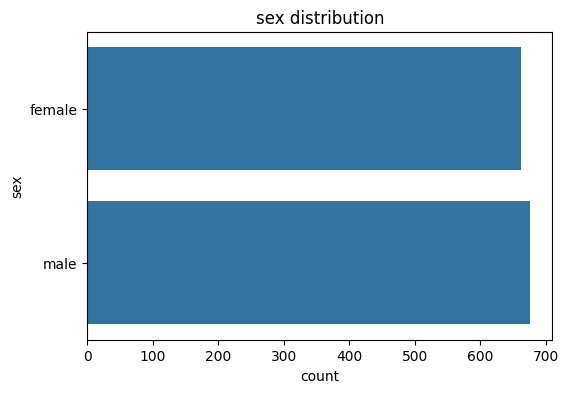

In [ ]:
fig = plt.figure(figsize=(6, 4))
sns.countplot(df['sex'])
plt.title('sex distribution')
plt.show()

In [ ]:
df['children'].value_counts()

,count
children,
0,574
1,324
2,240
3,157
4,25
5,18


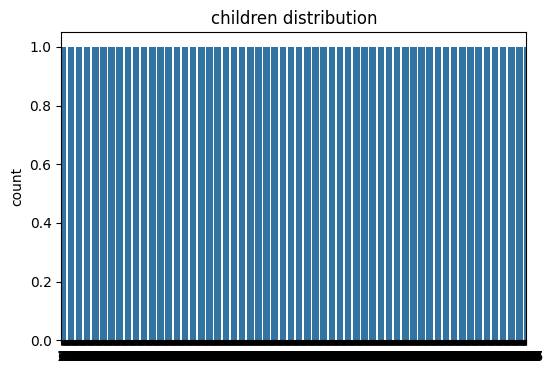

In [ ]:

fig = plt.figure(figsize=(6, 4))
sns.countplot(df['children'])
plt.title('children distribution')
plt.show()

In [ ]:

df['sex'] = pd.factorize(df['sex'])[0] + 1
df['region'] = pd.factorize(df['region'])[0] + 1
df['smoker'] = pd.factorize(df['smoker'])[0] + 1

corr = df.corr()
corr['charges'].sort_values(ascending=False)


,charges
charges,1.000000
age,0.299008
bmi,0.198341
children,0.067998
sex,0.057292
region,0.006208
smoker,-0.787251


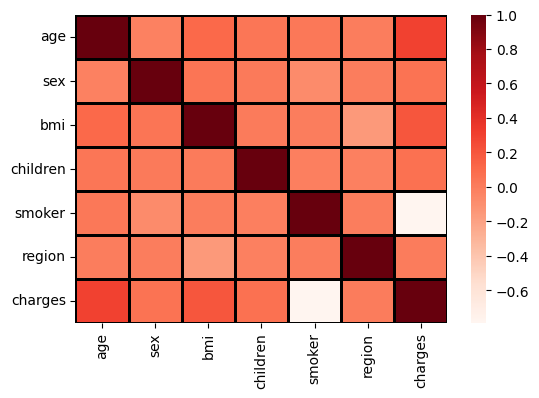

In [ ]:

fig = plt.figure(figsize=(6, 4))
data_plotting = df.corr(method='pearson')
sns.heatmap(data_plotting, cmap='Reds', linecolor='black', linewidths=2)
plt.show()


<Figure size 600x400 with 0 Axes>

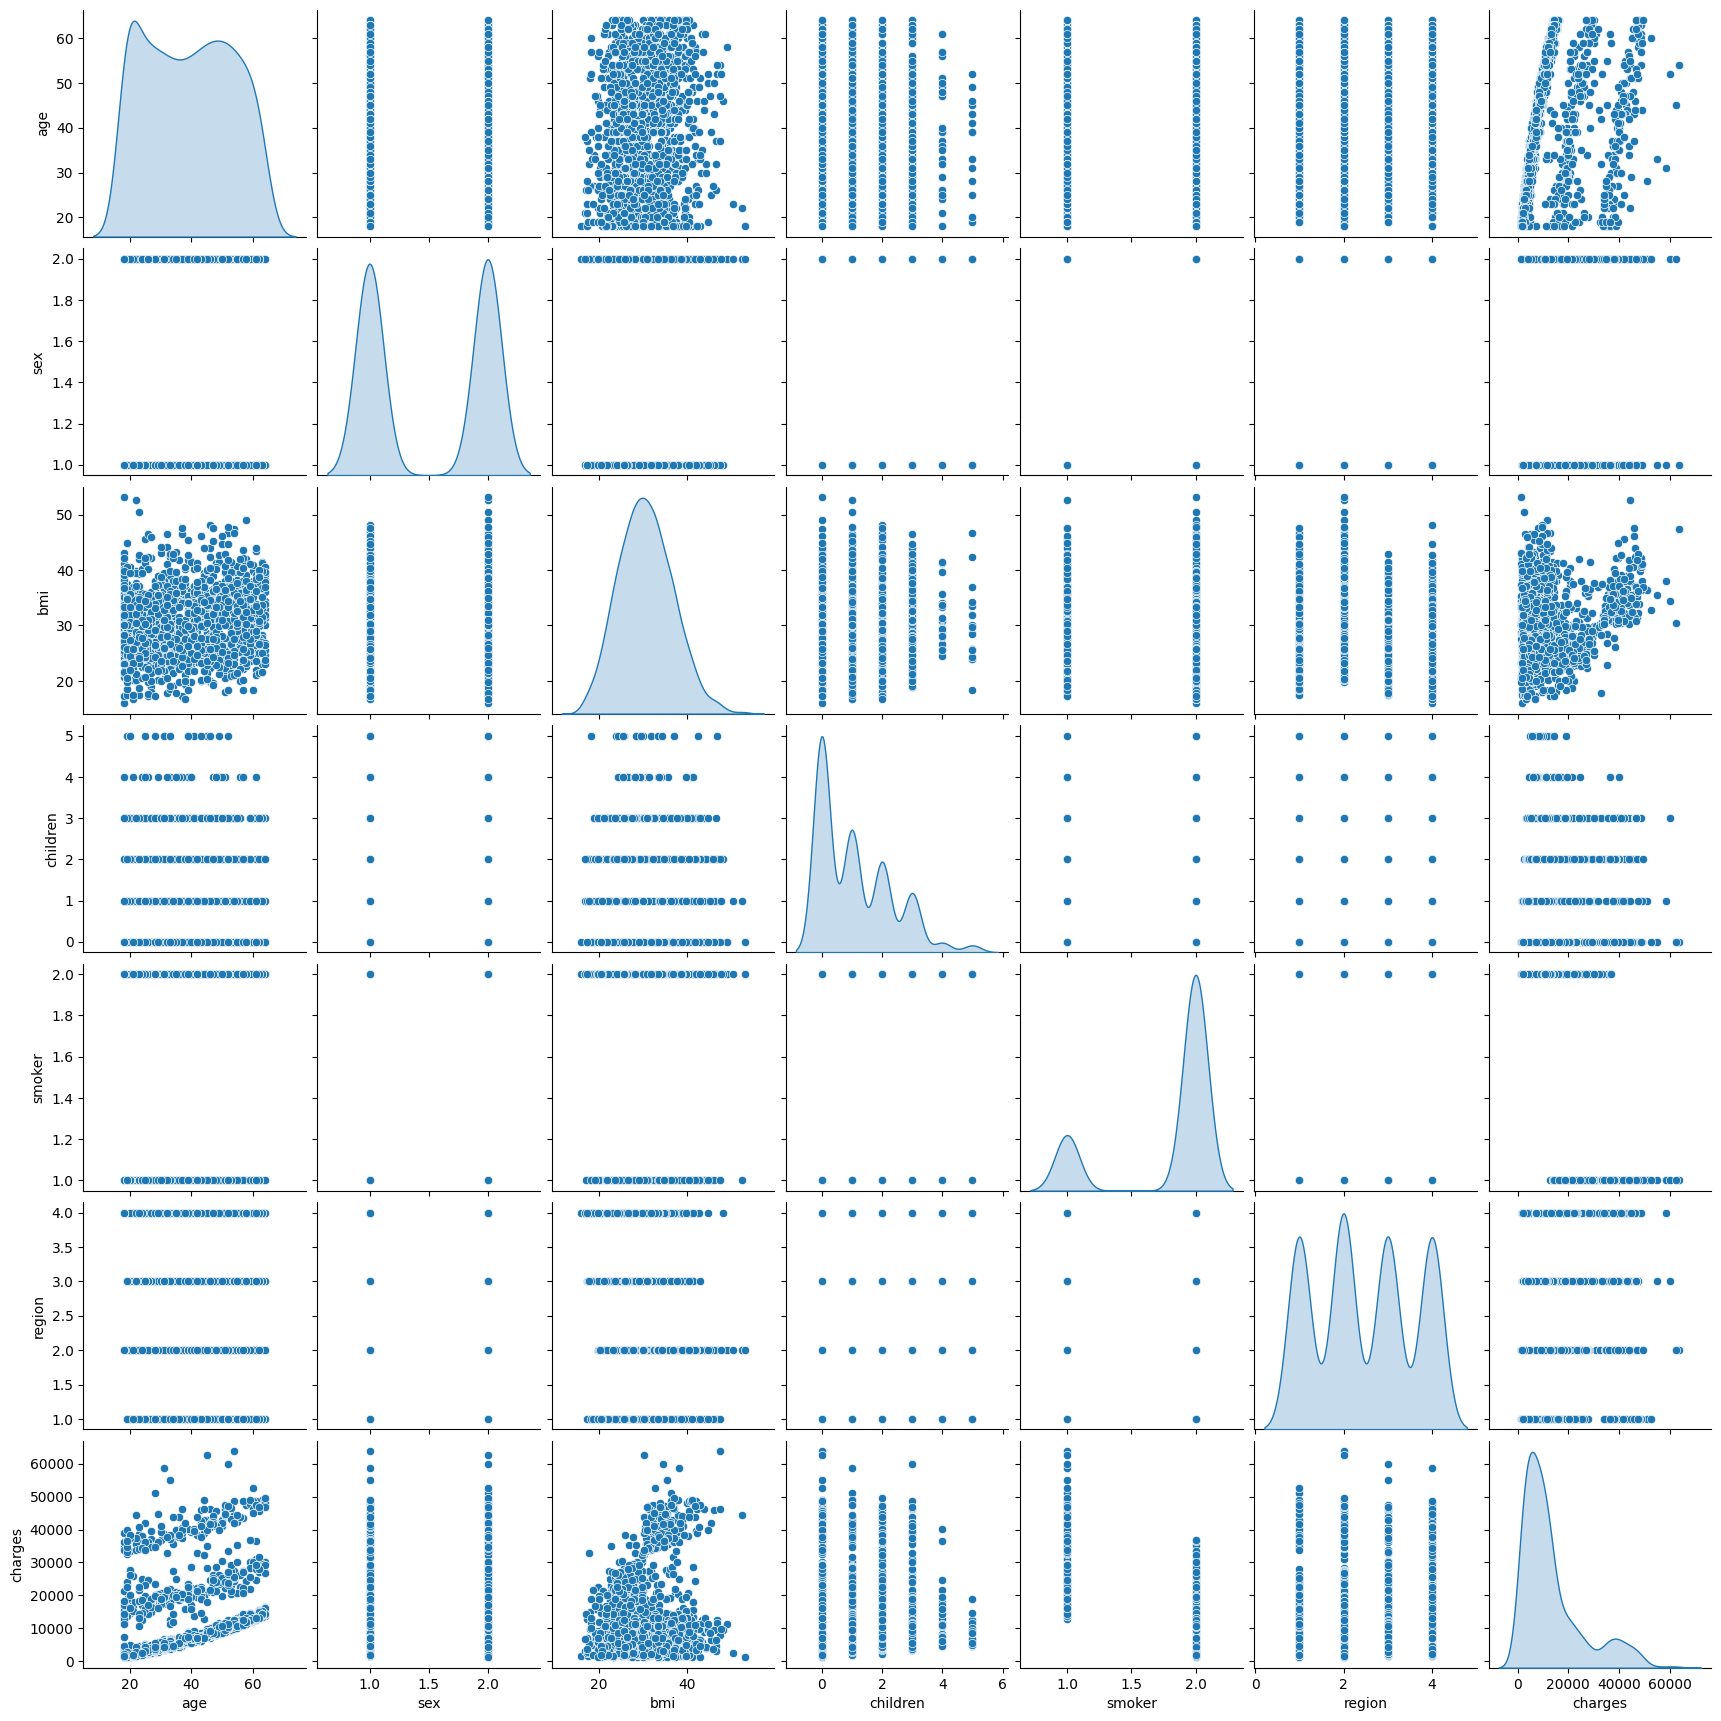

In [ ]:

fig = plt.figure(figsize=(6, 4))
sns.pairplot(df, diag_kind='kde')


In [ ]:

X = df.drop('charges', axis=1)
y = df['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=101
)


In [ ]:

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [ ]:
linear_reg_model = LinearRegression()
linear_reg_model.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:

y_pred = linear_reg_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)

MAE_li_reg = metrics.mean_absolute_error(y_test, y_pred)
MSE_li_reg = metrics.mean_squared_error(y_test, y_pred)
RMSE_li_reg = np.sqrt(MSE_li_reg)

pd.DataFrame(
    [MAE_li_reg, MSE_li_reg, RMSE_li_reg],
    index=['MAE_li_reg', 'MSE_li_reg', 'RMSE_li_reg'],
    columns=['Metrics']
)


,Metrics
MAE_li_reg,3.990250e+03
MSE_li_reg,3.353013e+07
RMSE_li_reg,5.790521e+03


In [ ]:

scores = cross_val_score(linear_reg_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))


[0.88791389 0.85653048 0.84404195 0.87198372 0.84417492]


In [ ]:

r2_score(y_test, linear_reg_model.predict(X_test_scaled))


0.7613126015198817

In [ ]:

Gradient_model = GradientBoostingRegressor()
Gradient_model.fit(X_train_scaled, y_train)


GradientBoostingRegressor()

In [ ]:

y_pred = Gradient_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)

MAE_gradient = metrics.mean_absolute_error(y_test, y_pred)
MSE_gradient = metrics.mean_squared_error(y_test, y_pred)
RMSE_gradient = np.sqrt(MSE_gradient)

pd.DataFrame(
    [MAE_gradient, MSE_gradient, RMSE_gradient],
    index=['MAE_gradient', 'MSE_gradient', 'RMSE_gradient'],
    columns=['Metrics']
)


,Metrics
MAE_gradient,2.528851e+03
MSE_gradient,2.110725e+07
RMSE_gradient,4.594262e+03


In [ ]:

scores = cross_val_score(Gradient_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))


[0.94595821 0.91415679 0.91686777 0.92464166 0.91695597]


In [ ]:

r2_score(y_test, Gradient_model.predict(X_test_scaled))


0.849746079970233

In [ ]:

XGB_model = XGBRegressor()
XGB_model.fit(X_train_scaled, y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=None,
             n_jobs=None, num_parallel_tree=None, ...)

In [ ]:

y_pred = XGB_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)

MAE_XGB = metrics.mean_absolute_error(y_test, y_pred)
MSE_XGB = metrics.mean_squared_error(y_test, y_pred)
RMSE_XGB = np.sqrt(MSE_XGB)

pd.DataFrame(
    [MAE_XGB, MSE_XGB, RMSE_XGB],
    index=['MAE_XGB', 'MSE_XGB', 'RMSE_XGB'],
    columns=['Metrics']
)


,Metrics
MAE_XGB,3.198314e+03
MSE_XGB,3.061846e+07
RMSE_XGB,5.533395e+03


In [ ]:

scores = cross_val_score(XGB_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))


[0.90787759 0.88795747 0.91289956 0.89459789 0.88672783]


In [ ]:

r2_score(y_test, XGB_model.predict(X_test_scaled))


0.7820396260594861

In [ ]:

tree_reg_model = DecisionTreeRegressor()
tree_reg_model.fit(X_train_scaled, y_train)


DecisionTreeRegressor()

In [ ]:

y_pred = tree_reg_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)

MAE_tree_reg = metrics.mean_absolute_error(y_test, y_pred)
MSE_tree_reg = metrics.mean_squared_error(y_test, y_pred)
RMSE_tree_reg = np.sqrt(MSE_tree_reg)

pd.DataFrame(
    [MAE_tree_reg, MSE_tree_reg, RMSE_tree_reg],
    index=['MAE_tree_reg', 'MSE_tree_reg', 'RMSE_tree_reg'],
    columns=['Metrics']
)


,Metrics
MAE_tree_reg,3.424019e+03
MSE_tree_reg,4.962887e+07
RMSE_tree_reg,7.044776e+03


In [ ]:

scores = cross_val_score(tree_reg_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))


[0.86159662 0.81170177 0.85618302 0.8648566  0.85786053]


In [ ]:

r2_score(y_test, tree_reg_model.predict(X_test_scaled))


0.6467121932981984

In [ ]:

forest_reg_model = RandomForestRegressor()
forest_reg_model.fit(X_train_scaled, y_train)


RandomForestRegressor()

In [ ]:

y_pred = forest_reg_model.predict(X_test_scaled)
y_pred = pd.DataFrame(y_pred)

MAE_forest_reg = metrics.mean_absolute_error(y_test, y_pred)
MSE_forest_reg = metrics.mean_squared_error(y_test, y_pred)
RMSE_forest_reg = np.sqrt(MSE_forest_reg)

pd.DataFrame(
    [MAE_forest_reg, MSE_forest_reg, RMSE_forest_reg],
    index=['MAE_forest_reg', 'MSE_forest_reg', 'RMSE_forest_reg'],
    columns=['Metrics']
)


,Metrics
MAE_forest_reg,2.876764e+03
MSE_forest_reg,2.511497e+07
RMSE_forest_reg,5.011483e+03


In [ ]:

scores = cross_val_score(forest_reg_model, X_train_scaled, y_train, cv=5)
print(np.sqrt(scores))


[0.93903709 0.90350685 0.92003903 0.91540383 0.90423467]


In [ ]:

r2_score(y_test, forest_reg_model.predict(X_test_scaled))


0.8212167507907862

# Avocado

In [10]:
!C:\pycaret-env\Scripts\python.exe -m ipykernel install --user --name pycaret311 --display-name "Python 3.11 (PyCaret)"

Installed kernelspec pycaret311 in C:\Users\송영은\AppData\Roaming\jupyter\kernels\pycaret311


In [5]:
import sys
print(sys.version)
print(sys.executable)

import pycaret
print("PyCaret 버전:", pycaret.__version__)

3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]
C:\pycaret-env\Scripts\python.exe
PyCaret 버전: 3.3.2


In [6]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [8]:
#Importing Libraries
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import pycaret
import warnings
import jinja2

from sklearn.preprocessing import LabelEncoder
from scipy import stats
from scipy.stats import *
from pycaret.regression import *

# Libraries Settings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

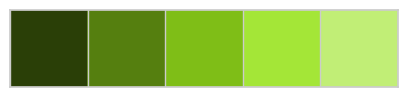

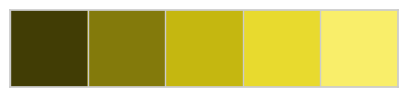

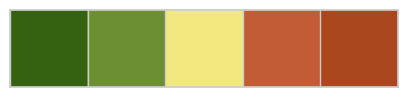

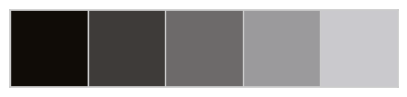

In [13]:
# Create List of Color Palletes
olive_grad = ['#2A3F07', '#557F0F', '#7FBE17', '#A4E637', '#C1EE76']
yellow_grad = ['#413D05', '#837A0B', '#C5B710', '#E8DA2E', '#F9EE6A']
color_mix = ['#356211', '#6C8F32', '#F2E880', '#C15C37', '#AA471F']
black_grad = ['#100C07', '#3E3B39', '#6D6A6A', '#9B9A9C', '#CAC9CD']

# Plot Color Palletes
sns.palplot(olive_grad)
sns.palplot(yellow_grad)
sns.palplot(color_mix)
sns.palplot(black_grad)

In [15]:
# Reading Dataset
ds = pd.read_csv('avocado.csv')
ds.head().style.background_gradient(cmap='Greens').set_properties(**{'font-family': 'Segoe UI'}).hide(axis='index')

Unnamed: 0,Date,AveragePrice,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region
0,2015-12-27,1.330000,64236.620000,1036.740000,54454.850000,48.160000,8696.870000,8603.620000,93.250000,0.000000,conventional,2015,Albany
1,2015-12-20,1.350000,54876.980000,674.280000,44638.810000,58.330000,9505.560000,9408.070000,97.490000,0.000000,conventional,2015,Albany
2,2015-12-13,0.930000,118220.220000,794.700000,109149.670000,130.500000,8145.350000,8042.210000,103.140000,0.000000,conventional,2015,Albany
3,2015-12-06,1.080000,78992.150000,1132.000000,71976.410000,72.580000,5811.160000,5677.400000,133.760000,0.000000,conventional,2015,Albany
4,2015-11-29,1.280000,51039.600000,941.480000,43838.390000,75.780000,6183.950000,5986.260000,197.690000,0.000000,conventional,2015,Albany


In [16]:
# Print Dataset Info
print('\033[92m\033[1m'+'.: Imported Dataset Info :.'+'\033[0m')
print('\033[92m*' * 30+'\033[0m')
print('Total Rows:'+'\033[92m\033[1m', ds.shape[0])
print('\033[0m'+'Total Columns:'+'\033[92m\033[1m', ds.shape[1])
print('\033[0m\033[92m'+'*' * 30+'\033[0m')
print('\n')

# Print Dataset Detail
print('\033[92m\033[1m'+'.: Dataset Details :.'+'\033[0m')
print('\033[0m\033[92m'+'*' * 30+'\033[0m')
ds.info(memory_usage = False)

.: Imported Dataset Info :.
******************************
Total Rows: 18249
Total Columns: 14
******************************


.: Dataset Details :.
******************************
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18249 entries, 0 to 18248
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Unnamed: 0    18249 non-null  int64  
 1   Date          18249 non-null  object 
 2   AveragePrice  18249 non-null  float64
 3   Total Volume  18249 non-null  float64
 4   4046          18249 non-null  float64
 5   4225          18249 non-null  float64
 6   4770          18249 non-null  float64
 7   Total Bags    18249 non-null  float64
 8   Small Bags    18249 non-null  float64
 9   Large Bags    18249 non-null  float64
 10  XLarge Bags   18249 non-null  float64
 11  type          18249 non-null  object 
 12  year          18249 non-null  int64  
 13  region        18249 non-null  object 
dtypes: float64(9), in

****************************************
.: Total Avocado based on each Type :.
****************************************


type
conventional    9126
organic         9123
Name: count, dtype: int64

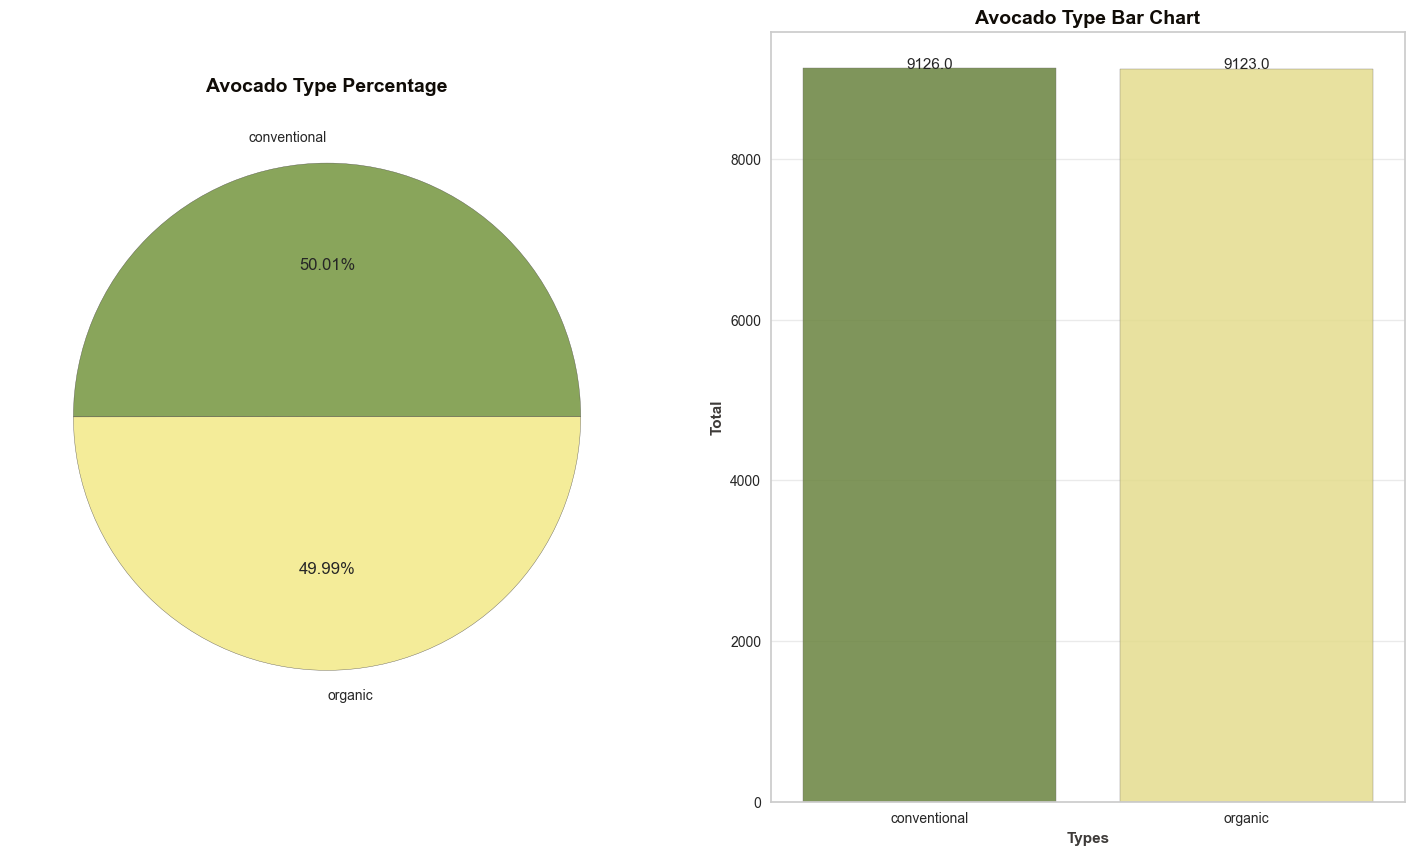

In [17]:
# Colors and Labels (Null Values Dropped)
colors = color_mix[1:3]
labels = ds['type'].dropna().unique()
order = ds['type'].value_counts().index

# Size for Both Figures
plt.figure(figsize=(18, 10))

# Pie Chart
plt.subplot(1, 2, 1)
plt.title('Avocado Type Percentage', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', 
          color = black_grad[0])
plt.pie(ds['type'].value_counts(), labels = order, colors = colors, 
        wedgeprops = dict(alpha = 0.8, edgecolor = black_grad[1]), autopct = '%.2f%%')

# Bar Chart
countplt = plt.subplot(1, 2, 2)
plt.title('Avocado Type Bar Chart', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
ax = sns.countplot(x = 'type', data = ds, palette = colors, order = order, edgecolor = black_grad[2], alpha = 0.85)
for rect in ax.patches:
    ax.text (rect.get_x()+rect.get_width()/2, rect.get_height()+0.75,rect.get_height(), horizontalalignment = 'center', 
             fontsize = 11)

plt.xlabel('Types', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Total', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
countplt

# Count Categorical Labels w/out Dropping Null Walues
print('\033[92m'+'*' * 40)
print('\033[92m\033[1m'+'.: Total Avocado based on each Type :.'+'\033[0m')
print('\033[92m'+'*' * 40+'\033[0m')
ds.type.value_counts(dropna=False)

***********************************
.: Total Avocado based on Year :.
***********************************


year
2017    5722
2016    5616
2015    5615
2018    1296
Name: count, dtype: int64

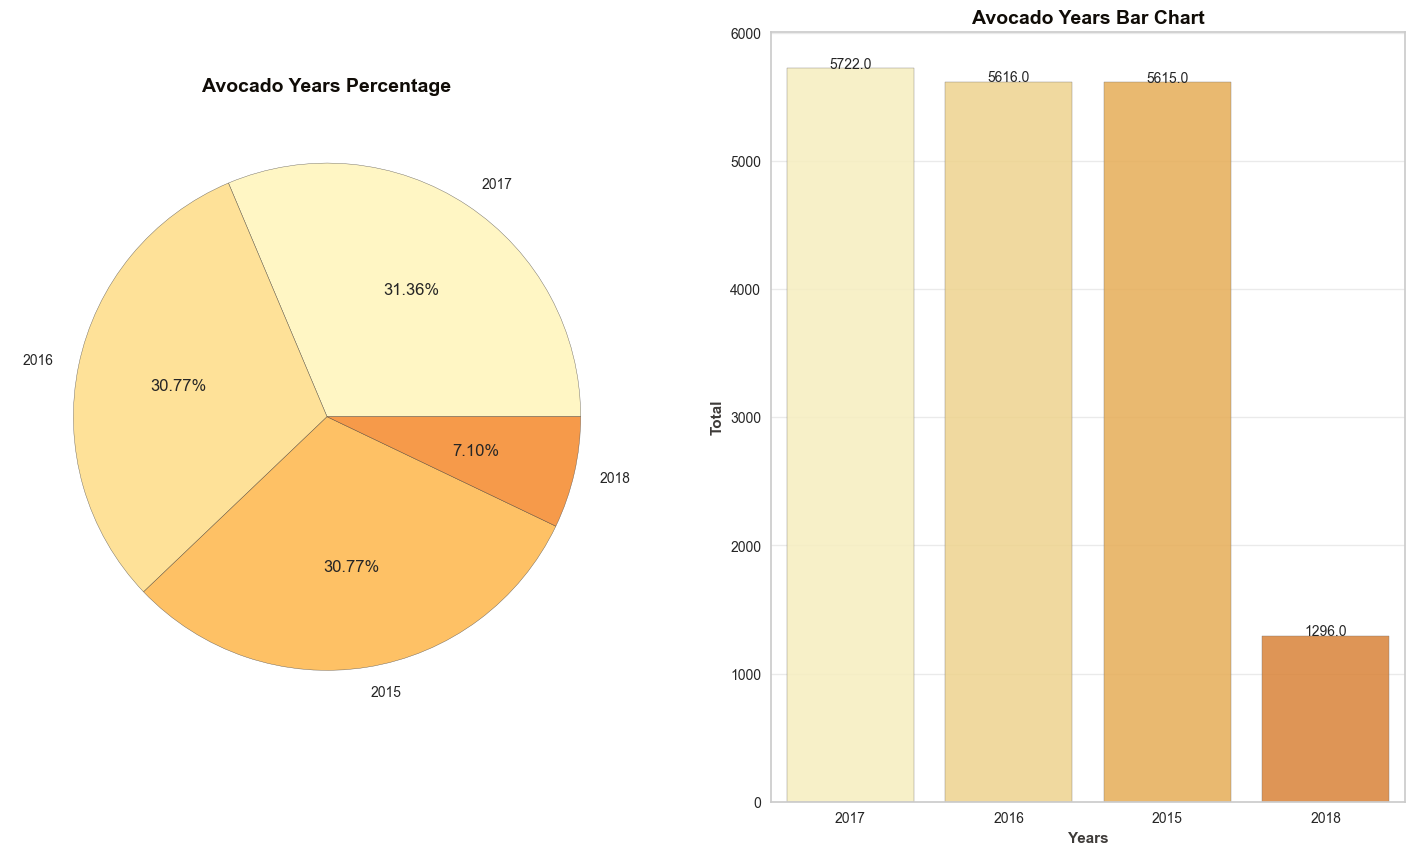

In [18]:
# Colors and Labels (Null Values Dropped)
colors = sns.color_palette('YlOrBr')
labels = ds['year'].dropna().unique()
order = ds['year'].value_counts().index

# Size for Both Figures
plt.figure(figsize=(18,10))

# Pie Chart
plt.subplot(1,2,1)
plt.title('Avocado Years Percentage', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
plt.pie(ds['year'].value_counts(), labels = order, colors = colors, 
        wedgeprops = dict(alpha = 0.8, edgecolor = black_grad[1]), autopct = '%.2f%%')

# Bar Chart
countplt = plt.subplot(1,2,2)
plt.title('Avocado Years Bar Chart', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
ax = sns.countplot(x = 'year', data = ds, palette = colors, order = order, edgecolor = black_grad[2], alpha = 0.85)
for rect in ax.patches:
    ax.text (rect.get_x()+rect.get_width()/2, rect.get_height()+0.75,rect.get_height(), horizontalalignment = 'center',
             fontsize = 10)

plt.xlabel('Years', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Total', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
countplt

# Count Categorical Labels w/out Dropping Null Walues
print('\033[92m'+'*' * 35)
print('\033[92m\033[1m'+'.: Total Avocado based on Year :.'+'\033[0m')
print('\033[92m'+'*' * 35+'\033[0m')
ds.year.value_counts(dropna=False)

In [19]:
# Count Categorical Labels w/Out Dropping Null Walues
print('\033[92m'+'*' * 38)
print('\033[92m\033[1m'+'.: Total Avocado based on Regions :.'+'\033[0m')
print('\033[92m'+'*' * 38)
ds.region.value_counts(dropna=False)

**************************************
.: Total Avocado based on Regions :.
**************************************


region
Albany                 338
Sacramento             338
Northeast              338
NorthernNewEngland     338
Orlando                338
Philadelphia           338
PhoenixTucson          338
Pittsburgh             338
Plains                 338
Portland               338
RaleighGreensboro      338
RichmondNorfolk        338
Roanoke                338
SanDiego               338
Atlanta                338
SanFrancisco           338
Seattle                338
SouthCarolina          338
SouthCentral           338
Southeast              338
Spokane                338
StLouis                338
Syracuse               338
Tampa                  338
TotalUS                338
West                   338
NewYork                338
NewOrleansMobile       338
Nashville              338
Midsouth               338
BaltimoreWashington    338
Boise                  338
Boston                 338
BuffaloRochester       338
California             338
Charlotte              338
Chicago              

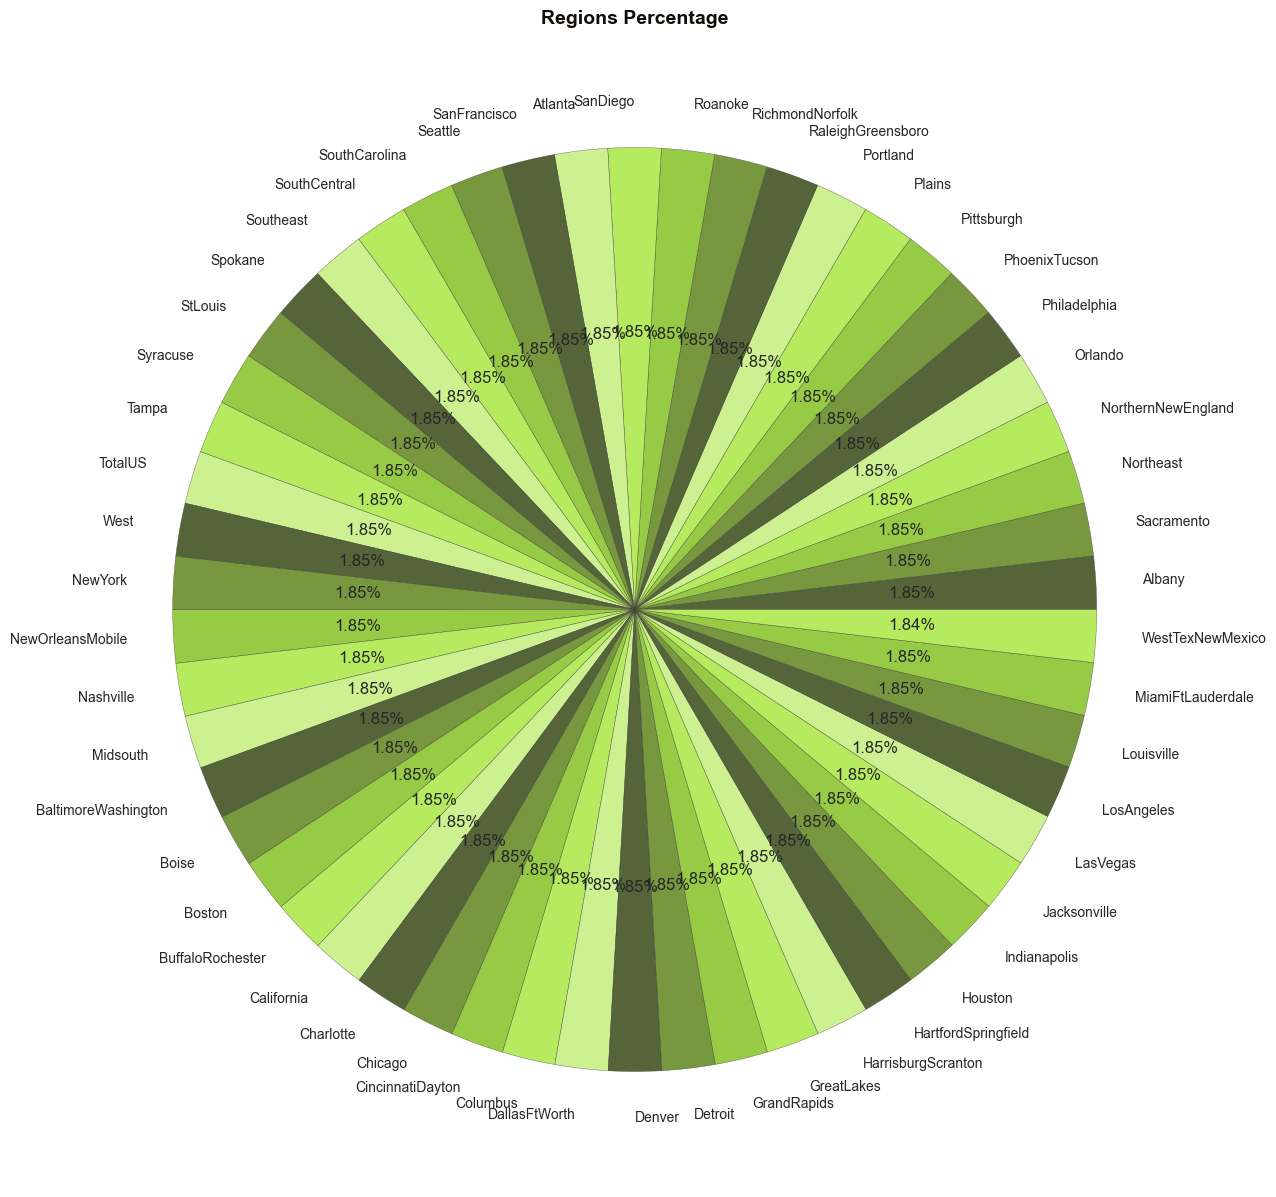

In [20]:
# Colors and Labels (Null Values Dropped)
colors = olive_grad[0:5]
labels = ds['region'].dropna().unique()
order = ds['region'].value_counts().index

# Pie Chart
plt.figure(figsize = (15, 15))
plt.title('Regions Percentage', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
plt.pie(ds['region'].value_counts(), labels = order, colors = colors, 
        wedgeprops = dict(alpha = 0.8, edgecolor = black_grad[1]), autopct = '%.2f%%');

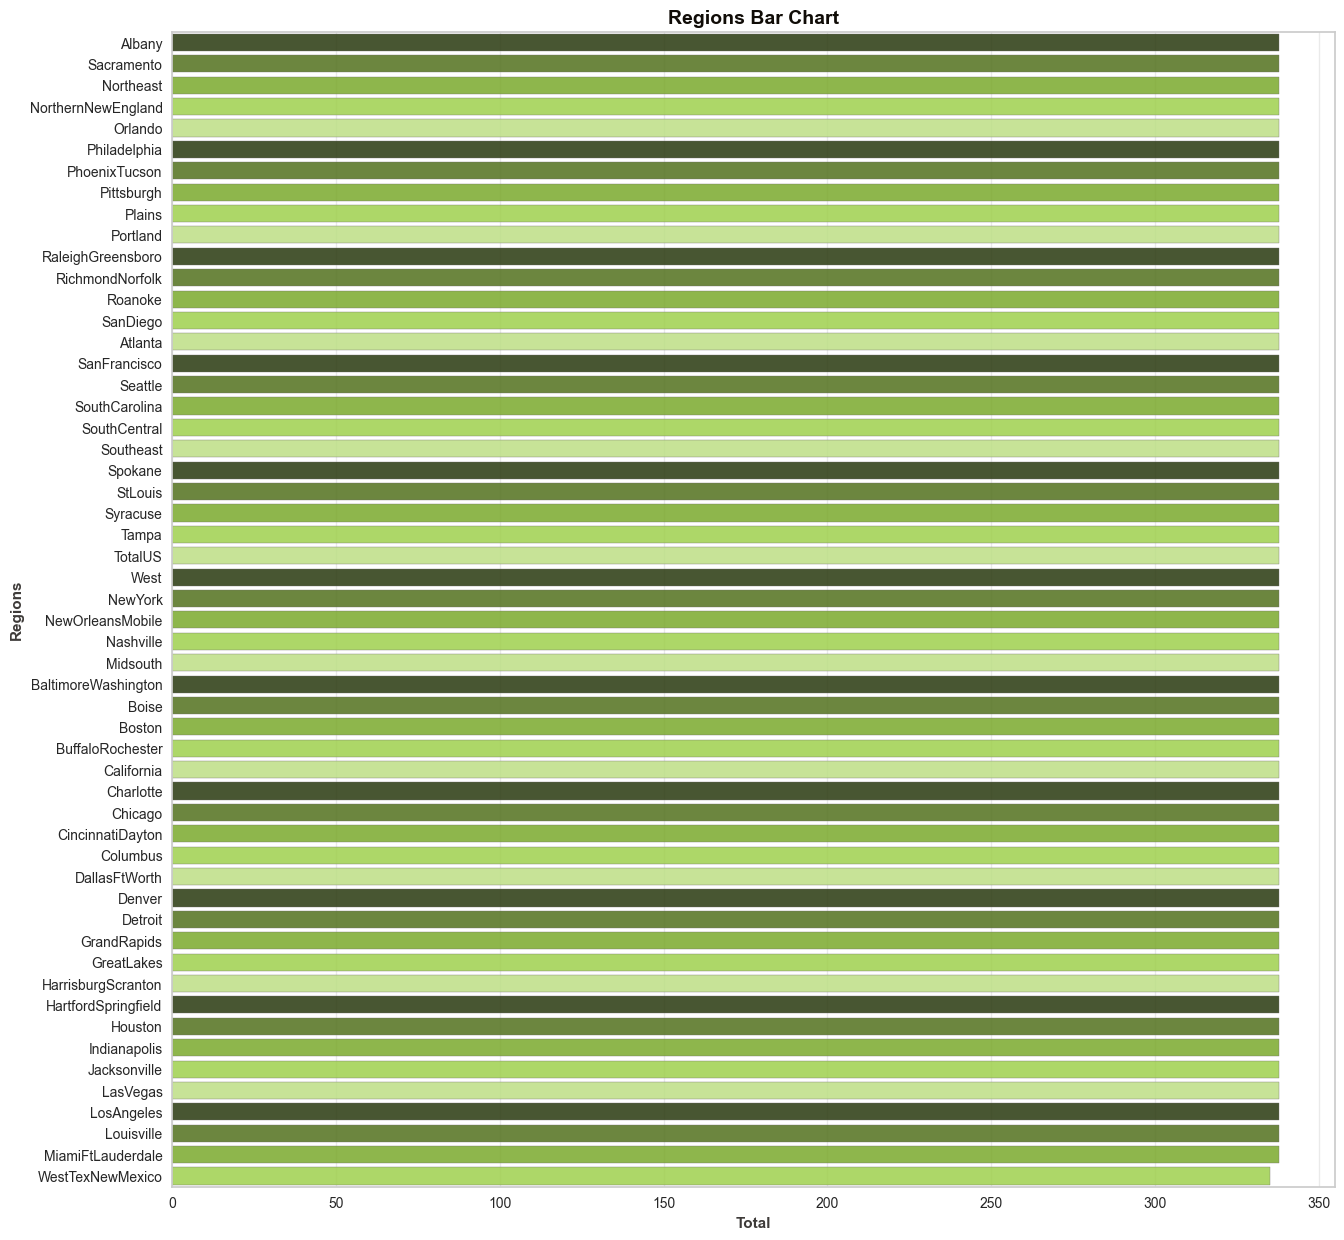

In [21]:
# Bar Chart
plt.figure(figsize = (15, 15))
plt.title('Regions Bar Chart', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif', color = black_grad[0])
sns.countplot(y = 'region', data = ds, order = order, palette = colors, edgecolor = black_grad[2], alpha = 0.85)
plt.xlabel('Total', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Regions', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'x', alpha = 0.4);

In [22]:
# Descriptive Statistics
ds[['AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 
    'XLarge Bags']].describe().T.style.background_gradient(cmap='YlOrBr').set_properties(**{'font-family': 'Segoe UI'})

,count,mean,std,min,25%,50%,75%,max
AveragePrice,18249.000000,1.405978,0.402677,0.440000,1.100000,1.370000,1.660000,3.250000
Total Volume,18249.000000,850644.013009,3453545.355399,84.560000,10838.580000,107376.760000,432962.290000,62505646.520000
4046,18249.000000,293008.424531,1264989.081763,0.000000,854.070000,8645.300000,111020.200000,22743616.170000
4225,18249.000000,295154.568356,1204120.401135,0.000000,3008.780000,29061.020000,150206.860000,20470572.610000
4770,18249.000000,22839.735993,107464.068435,0.000000,0.000000,184.990000,6243.420000,2546439.110000
Total Bags,18249.000000,239639.202060,986242.399216,0.000000,5088.640000,39743.830000,110783.370000,19373134.370000
Small Bags,18249.000000,182194.686696,746178.514962,0.000000,2849.420000,26362.820000,83337.670000,13384586.800000
Large Bags,18249.000000,54338.088145,243965.964547,0.000000,127.470000,2647.710000,22029.250000,5719096.610000
XLarge Bags,18249.000000,3106.426507,17692.894652,0.000000,0.000000,0.000000,132.500000,551693.650000


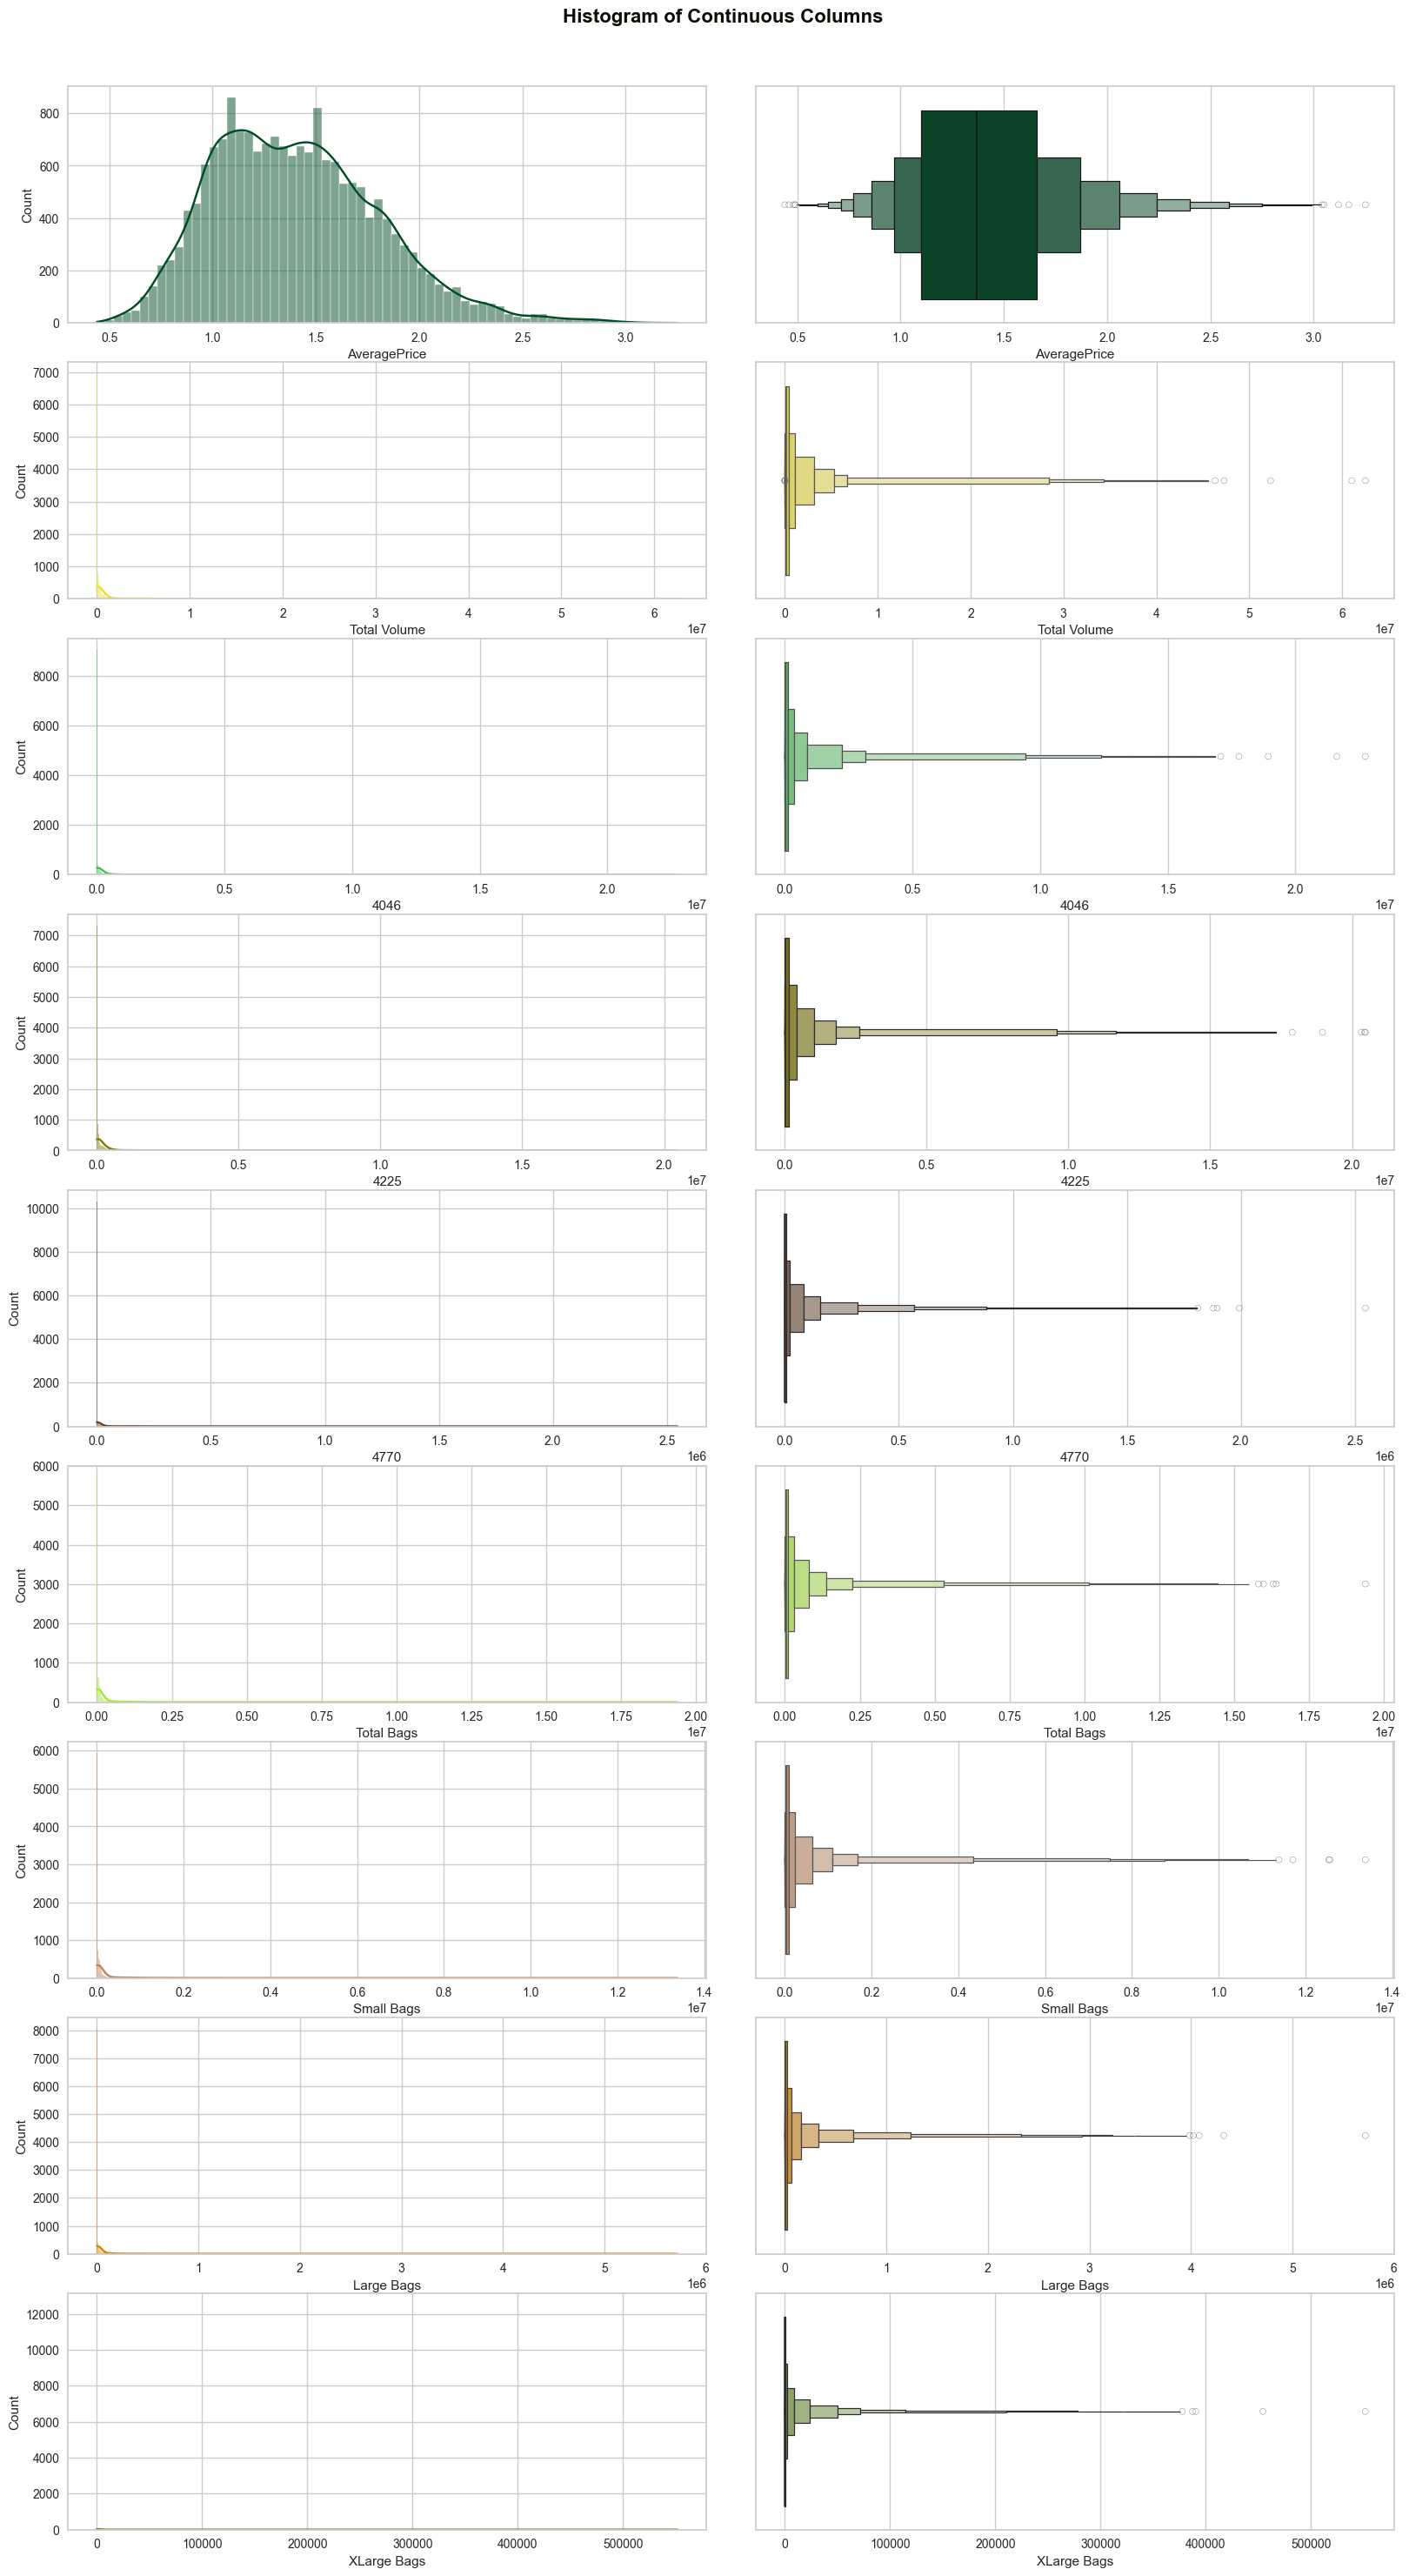

In [23]:
# Plot Size
fig, axs = plt.subplots(9, 2, figsize = (16, 30))

# General Title
fig.tight_layout()
fig.subplots_adjust(top = 0.95)
fig.suptitle('Histogram of Continuous Columns', fontweight = 'bold', fontsize = 16, fontfamily = 'sans-serif', 
             color = black_grad[0])

# Continuous Variables (Row 1)
sns.histplot(data = ds, x = 'AveragePrice', kde = True, ax = axs[0, 0], color = '#004D25')
sns.boxenplot(data = ds, x = 'AveragePrice', ax = axs[0, 1], color = '#004D25')

# Continuous Variables (Row 2)
sns.histplot(data = ds, x = 'Total Volume', kde = True, ax = axs[1, 0], color = '#EDDE30')
sns.boxenplot(data = ds, x = 'Total Volume', ax = axs[1, 1], color = '#EDDE30')

# Continuous Variables (Row 3)
sns.histplot(data = ds, x='4046', kde = True, ax = axs[2, 0], color = '#48BF53')
sns.boxenplot(data = ds, x = '4046', ax = axs[2, 1], color = '#48BF53')

# Continuous Variables (Row 4)
sns.histplot(data = ds, x = '4225', kde = True, ax = axs[3, 0], color = '#837A0B')
sns.boxenplot(data = ds, x = '4225', ax = axs[3, 1], color = '#837A0B')

# Continuous Variables (Row 5)
sns.histplot(data = ds, x = '4770', kde = True, ax = axs[4, 0], color = '#664228')
sns.boxenplot(data = ds, x = '4770', ax = axs[4, 1], color = '#664228')

# Continuous Variables (Row 6)
sns.histplot(data = ds, x = 'Total Bags', kde = True, ax = axs[5, 0], color = '#A4E637')
sns.boxenplot(data = ds, x = 'Total Bags', ax = axs[5, 1], color = '#A4E637')

# Continuous Variables (Row 7)
sns.histplot(data = ds, x = 'Small Bags', kde = True, ax = axs[6, 0], color = '#BF865D')
sns.boxenplot(data = ds, x = 'Small Bags', ax = axs[6, 1], color = '#BF865D')

# Continuous Variables (Row 8)
sns.histplot(data = ds, x = 'Large Bags', kde = True, ax = axs[7, 0], color = '#D98000')
sns.boxenplot(data = ds, x = 'Large Bags', ax = axs[7, 1], color = '#D98000')

# Continuous Variables (Row 9)
sns.histplot(data = ds, x = 'XLarge Bags', kde = True, ax = axs[8, 0], color = '#557F0F')
sns.boxenplot(data = ds, x = 'XLarge Bags', ax = axs[8, 1], color = '#557F0F');

In [24]:
# Skewness of Continuous Variables
print('\033[92m\033[1m'+'.: Continuous Columns Skewness :.'+'\033[0m')
print('\033[92m*' * 34+'\033[0m')
ds[['AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 
    'XLarge Bags']].skew(axis = 0, skipna = True)

.: Continuous Columns Skewness :.
**********************************


AveragePrice     0.580303
Total Volume     9.007687
4046             8.648220
4225             8.942466
4770            10.159396
Total Bags       9.756072
Small Bags       9.540660
Large Bags       9.796455
XLarge Bags     13.139751
dtype: float64

In [25]:
# Kurtoisis of Continuous Variables
print('\033[92m\033[1m'+'.: Continuous Columns Kurtosis :.'+'\033[0m')
print('\033[92m*' * 34+'\033[0m')
ds[['AveragePrice', 'Total Volume', '4046', '4225', '4770', 'Total Bags', 'Small Bags', 'Large Bags', 
    'XLarge Bags']].kurt(axis = 0, skipna = True)

.: Continuous Columns Kurtosis :.
**********************************


AveragePrice      0.325196
Total Volume     92.104458
4046             86.809113
4225             91.949022
4770            132.563441
Total Bags      112.272156
Small Bags      107.012885
Large Bags      117.999481
XLarge Bags     233.602612
dtype: float64

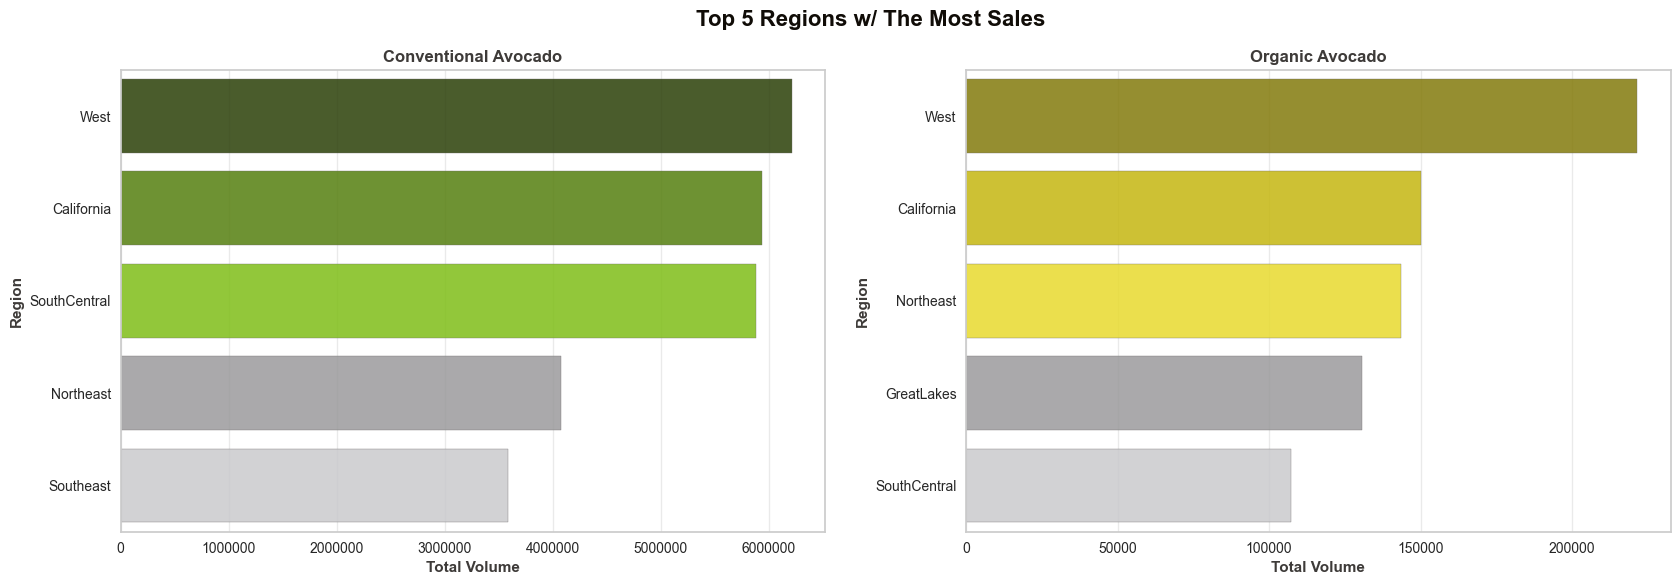

In [31]:
# Create New Dataframes based on Type
eda0 = ds[['region', 'Total Volume']][ds.type == 'conventional']
eda0 = eda0[eda0['region'] != 'TotalUS']
eda0 = eda0.groupby(['region']).aggregate({'Total Volume': np.mean}).sort_values(by = 'Total Volume',
                                                                                 ascending = False).iloc[:5]

eda1 = ds[['region', 'Total Volume']][ds.type == 'organic']
eda1 = eda1[eda1['region'] != 'TotalUS']
eda1 = eda1.groupby(['region']).aggregate({'Total Volume': np.mean}).sort_values(by = 'Total Volume', 
                                                                                 ascending = False).iloc[:5]

# General Settings of Bar Charts
fig, ax = plt.subplots(1, 2, figsize = (20, 6))
fig.suptitle('Top 5 Regions w/ The Most Sales', fontweight = 'heavy', fontsize = 16, fontfamily = 'sans-serif',
             color = black_grad[0])

# Bar Chart Left
plt.subplot(1, 2, 1)
plt.title('Conventional Avocado', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
bar_left = sns.barplot(x='Total Volume', y = eda0.index, data = eda0, palette = black_grad, edgecolor = black_grad[2], 
                       alpha = 0.85)
bar_left.patches[0].set_facecolor(olive_grad[0])
bar_left.patches[1].set_facecolor(olive_grad[1])
bar_left.patches[2].set_facecolor(olive_grad[2])
plt.xlabel('Total Volume', fontweight='bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0)
plt.grid(axis = 'x', alpha = 0.4)
plt.ticklabel_format(style = 'plain', axis = 'x')

# Bar Chart Right
plt.subplot(1, 2, 2)
plt.title('Organic Avocado', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
bar_right = sns.barplot(x='Total Volume', y = eda1.index, data = eda1, palette = black_grad, edgecolor = black_grad[2],
                        alpha = 0.85)
bar_right.patches[0].set_facecolor(yellow_grad[1])
bar_right.patches[1].set_facecolor(yellow_grad[2])
bar_right.patches[2].set_facecolor(yellow_grad[3])
plt.xlabel('Total Volume', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0)
plt.grid(axis = 'x', alpha = 0.4)
plt.ticklabel_format(style = 'plain', axis = 'x')
plt.show();

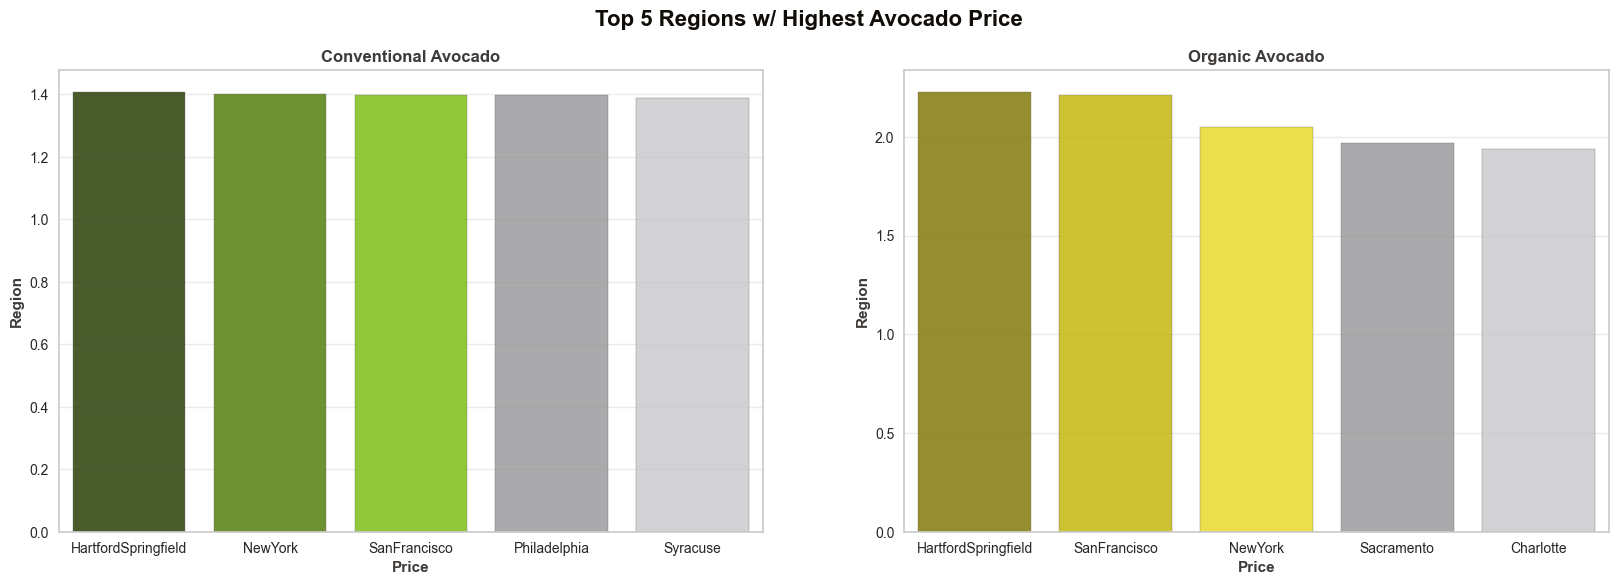

In [32]:
# Create New Dataframes based on Type
eda2 = ds[['region', 'AveragePrice']][ds.type == 'conventional']
eda2 = eda2.groupby(['region']).aggregate({'AveragePrice': np.mean}).sort_values(by = 'AveragePrice', 
                                                                                 ascending = False).iloc[:5]

eda3 = ds[['region', 'AveragePrice']][ds.type == 'organic']
eda3 = eda3.groupby(['region']).aggregate({'AveragePrice': np.mean}).sort_values(by = 'AveragePrice',
                                                                                 ascending = False).iloc[:5]

# General Settings of Bar Charts
fig, ax = plt.subplots(1, 2, figsize = (20, 6))
fig.suptitle('Top 5 Regions w/ Highest Avocado Price', fontweight = 'heavy', fontsize = 16, fontfamily = 'sans-serif', 
             color = black_grad[0])

# Bar Chart Left
plt.subplot(1, 2, 1)
plt.title('Conventional Avocado', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
bar_left = sns.barplot(y = 'AveragePrice', x = eda2.index, data = eda2, palette = black_grad, edgecolor = black_grad[2],
                       alpha = 0.85)
bar_left.patches[0].set_facecolor(olive_grad[0])
bar_left.patches[1].set_facecolor(olive_grad[1])
bar_left.patches[2].set_facecolor(olive_grad[2])
plt.xlabel('Price', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.ticklabel_format(style = 'plain', axis = 'y')

# Bar Chart Right
plt.subplot(1, 2, 2)
plt.title('Organic Avocado', fontweight = 'bold', fontsize = '12', fontfamily = 'sans-serif', color = black_grad[1])
bar_right = sns.barplot(y='AveragePrice', x = eda3.index, data = eda3, palette = black_grad, edgecolor = black_grad[2],
                        alpha = 0.85)
bar_right.patches[0].set_facecolor(yellow_grad[1])
bar_right.patches[1].set_facecolor(yellow_grad[2])
bar_right.patches[2].set_facecolor(yellow_grad[3])
plt.xlabel('Price', fontweight='bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Region', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.ticklabel_format(style = 'plain', axis = 'y')
plt.show();

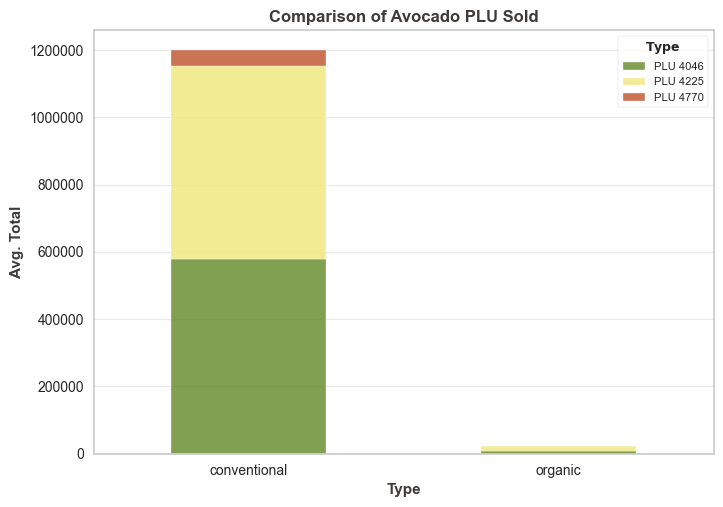

In [34]:
# Creating New Data Frame
eda30 = ds[['type', '4046', '4225', '4770']]
eda30 = eda30.groupby(['type']).aggregate({'4046': np.mean, '4225': np.mean, '4770': np.mean})

# Stacked Bar Chart
eda30.plot(kind='bar', stacked = True, color = color_mix[-4:-1], alpha = 0.85)
plt.title('Comparison of Avocado PLU Sold', fontweight = 'bold', fontsize = '12', fontfamily = 'sans-serif', 
          color = black_grad[1])
plt.xlabel('Type', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Avg. Total', fontweight = 'bold', fontsize = '11', fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.legend(labels = ['PLU 4046','PLU 4225', 'PLU 4770'], title = '$\\bf{Type}$', fontsize = '8', title_fontsize = '9',
           loc = 'upper right', frameon = True)
plt.xticks(rotation = 0)
plt.ticklabel_format(style = 'plain', axis = 'y');

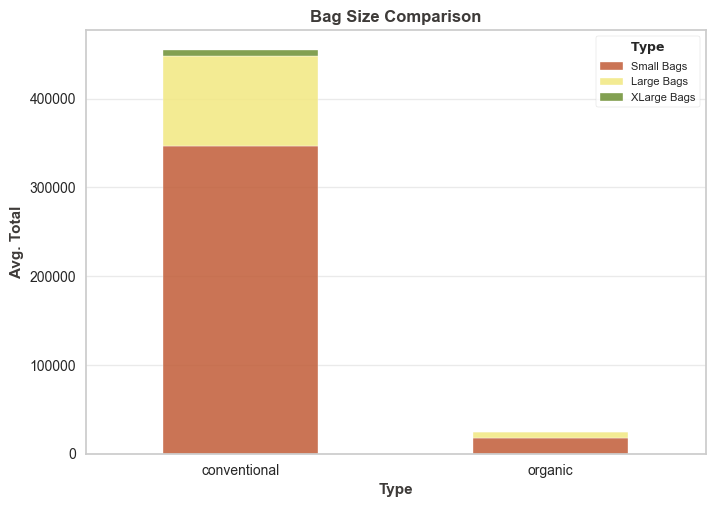

In [36]:
# Creating New Data Frame
eda31 = ds[['type', 'Small Bags', 'Large Bags', 'XLarge Bags']]
eda31 = eda31.groupby(['type']).aggregate({'Small Bags': 'mean', 'Large Bags': 'mean', 'XLarge Bags': 'mean'})
# Stacked Bar Chart
eda31.plot(kind = 'bar', stacked = True, color = color_mix[3:0:-1], alpha = 0.85)
plt.title('Bag Size Comparison', fontweight = 'bold', fontsize = 12, fontfamily = 'sans-serif', color = black_grad[1])
plt.xlabel('Type', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Avg. Total', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.grid(axis = 'y', alpha = 0.4)
plt.grid(axis = 'x', alpha = 0)
plt.legend(labels = ['Small Bags','Large Bags', 'XLarge Bags'], title = '$\\bf{Type}$', fontsize = 8, title_fontsize = 9,
           loc = 'upper right', frameon = True)
plt.xticks(rotation = 0)
plt.ticklabel_format(style = 'plain', axis = 'y');

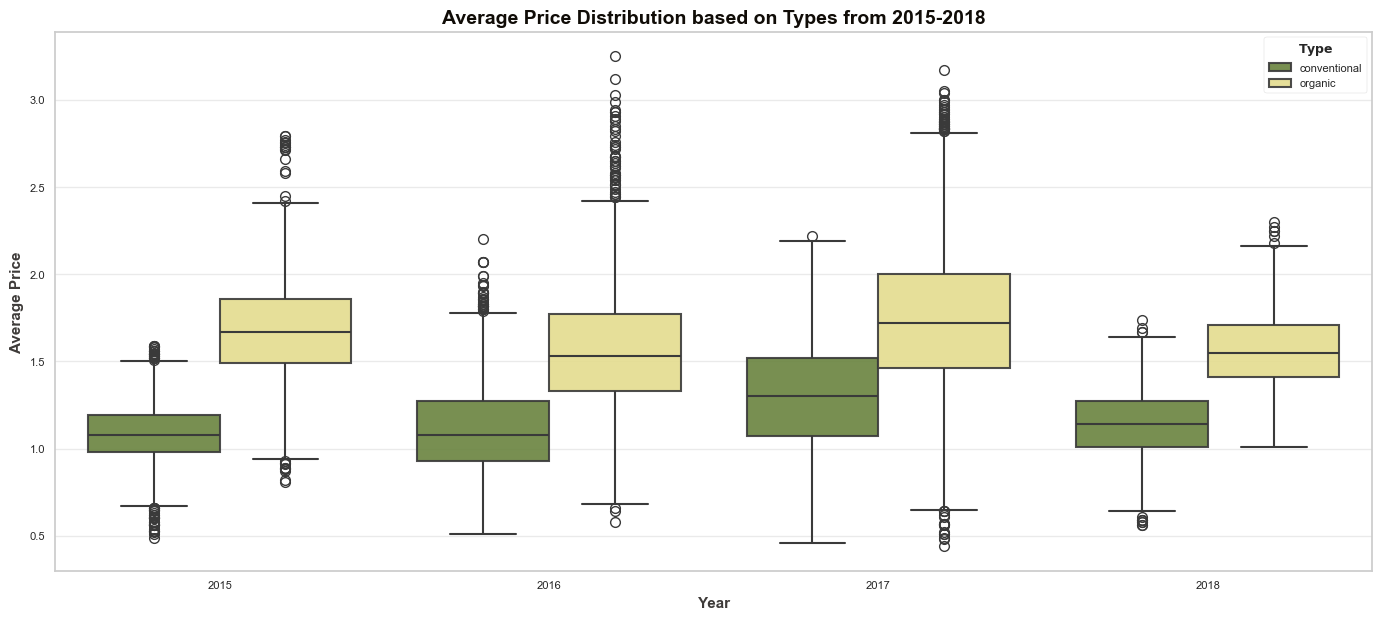

In [37]:
# Creating Box Plot based on Type
fig, ax = plt.subplots()
fig.set_size_inches(17, 7)
plt.title('Average Price Distribution based on Types from 2015-2018', fontweight='bold', fontsize = 14, 
          fontfamily = 'sans-serif', color = black_grad[0])
sns.boxplot(x = 'year', y = 'AveragePrice', hue = 'type', data = ds, ax = ax, palette = color_mix[1:3], 
            boxprops = dict(alpha = 0.9), linewidth = 1.5)
plt.xlabel('Year', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Average Price', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.xticks(fontsize = 8)
plt.yticks(fontsize = 8)
plt.legend(title = '$\\bf{Type}$', fontsize = 8, title_fontsize = 9, loc = 'upper right', frameon = True)
plt.grid(axis = 'y', alpha = 0.4)
plt.show()

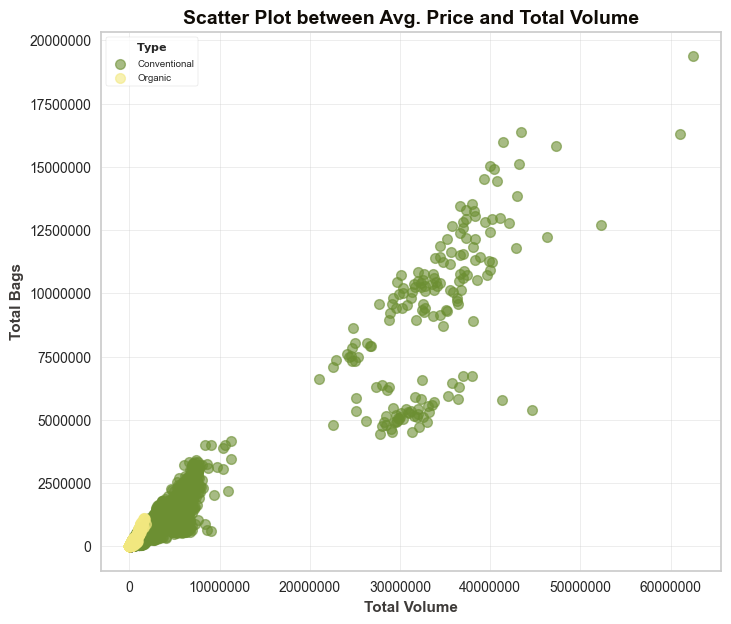

In [38]:
# Seperating Total Volume & Total Bags based on Type
x0 = ds.xs('Total Volume', axis = 1)[ds.type == 'conventional']
x1 = ds.xs('Total Volume', axis = 1)[ds.type == 'organic']
y0 = ds.xs('Total Bags', axis = 1)[ds.type == 'conventional']
y1 = ds.xs('Total Bags', axis = 1)[ds.type == 'organic']

# Creating Scatter Plot
plt.figure(figsize = (8, 7))
plt.title('Scatter Plot between Avg. Price and Total Volume', fontweight = 'bold', fontsize = 14, 
          fontfamily = 'sans-serif', color = black_grad[0])
plt.scatter(x = x0, y = y0, c = color_mix[1], alpha = 0.6, linewidths = 1)
plt.scatter(x = x1, y = y1, c = color_mix[2], alpha = 0.6, linewidths = 1)
plt.legend(['Conventional', 'Organic'], title = '$\\bf{Type}$', fontsize = 7, title_fontsize = 8, loc = 'upper left',
           frameon = True)
plt.xlabel('Total Volume', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ylabel('Total Bags', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif', color = black_grad[1])
plt.ticklabel_format(style = 'plain', axis = 'both')
plt.grid(axis = 'both', alpha = 0.5, lw = 0.5)
plt.show()

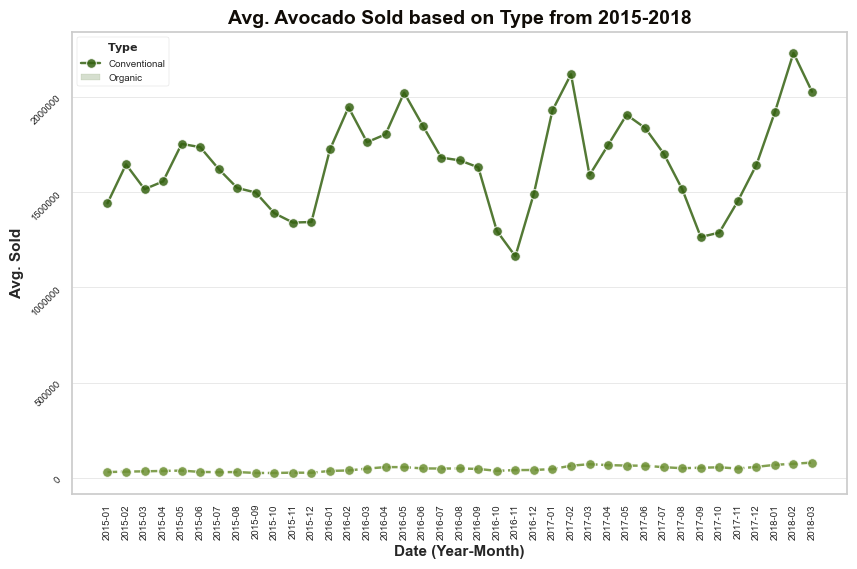

In [40]:
# Calculating Mean of `Total Volume` grouped by Type and Date
dseda8 = ds[['Date', 'Total Volume', 'type']].copy()
dseda8['Date'] = pd.DatetimeIndex(dseda8['Date'])
dseda8['Date'] = dseda8['Date'].apply(lambda x: x.strftime('%Y-%m'))
group8 = dseda8.groupby(['Date', 'type'])
mnth_avg8 = group8.aggregate({'Total Volume': 'mean'})
# Creating Time Series Plot of Avg. Price
plt.figure(figsize = (10, 6))
plt.title('Avg. Avocado Sold based on Type from 2015-2018', fontweight = 'bold', fontsize = 14,
          fontfamily = 'sans-serif', color = black_grad[0])
sns.lineplot(data = mnth_avg8, x = 'Date', y = 'Total Volume', hue = 'type', style = 'type', markers = ['o', 'o'],
             palette = color_mix[0:2], alpha = 0.85)
plt.xlabel('Date (Year-Month)', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ylabel('Avg. Sold', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation = 90, fontsize = 7)
plt.yticks(rotation = 45, fontsize = 7)
plt.grid(axis='y', alpha = 0.5, lw = 0.6)
plt.grid(axis='x', alpha = 0)
plt.legend(labels = ['Conventional', 'Organic'], title = '$\\bf{Type}$', fontsize = 7, title_fontsize = 8, frameon=True);

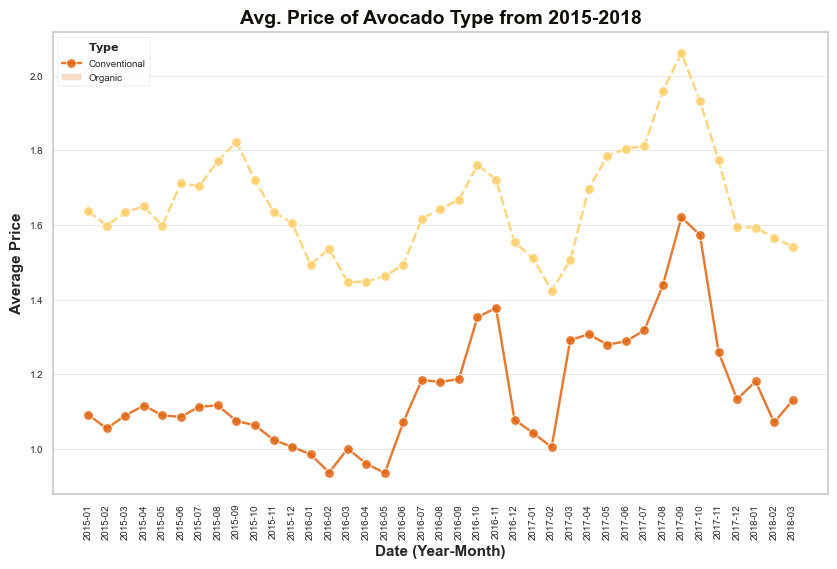

In [41]:
# Calculating Mean of `AveragePrice` grouped by Type and Date
dseda9 = ds[['Date', 'AveragePrice', 'type']].copy()
dseda9['Date'] = pd.DatetimeIndex(dseda9['Date'])
dseda9['Date'] = dseda9['Date'].apply(lambda x: x.strftime('%Y-%m'))
group9 = dseda9.groupby(['Date', 'type'])
mnth_avg9 = group9.aggregate({'AveragePrice': 'mean'})
# Creating Time Series Plot of Avg. Price
plt.figure(figsize = (10, 6))
plt.title('Avg. Price of Avocado Type from 2015-2018', fontweight = 'bold', fontsize = 14, fontfamily = 'sans-serif',
          color = black_grad[0])
sns.lineplot(data = mnth_avg9, x = 'Date', y = 'AveragePrice', hue = 'type', style = 'type', markers = ['o', 'o'],
             palette = 'YlOrBr_r', alpha = 0.85)
plt.xlabel('Date (Year-Month)', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ylabel('Average Price', fontweight = 'bold', fontsize = 11, fontfamily = 'sans-serif')
plt.ticklabel_format(style = 'plain', axis = 'y')
plt.xticks(rotation = 90, fontsize = 7)
plt.yticks(fontsize = 7)
plt.grid(axis = 'y', alpha = 0.5, lw = 0.6)
plt.grid(axis = 'x', alpha = 0)
plt.legend(labels = ['Conventional', 'Organic'], title = '$\\bf{Type}$', fontsize = 7, title_fontsize = 8,
           loc = 'upper left', frameon = True);

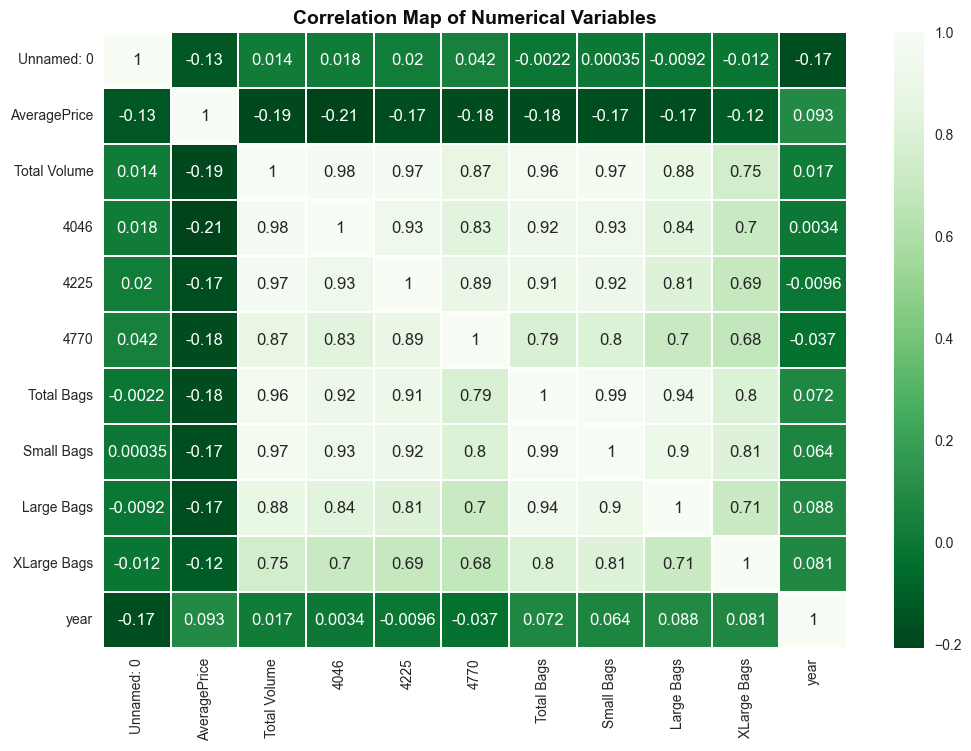

In [43]:
# Correlation Map (Heatmap)
plt.figure(figsize = (12, 8))
sns.heatmap(ds.corr(numeric_only=True), annot = True, cmap = 'Greens_r', linewidths = 0.1)
plt.title('Correlation Map of Numerical Variables', fontsize = 14, fontweight = 'bold', fontfamily = 'sans-serif',
          color = black_grad[0]);

In [44]:
# Change `Date` Format to 'datetime'
ds.Date = pd.to_datetime(ds.Date)
# Extracting Month Number from `Date`
ds['month'] = pd.DatetimeIndex(ds['Date']).month

In [45]:
# Setup PyCaret Regression Module
avc = setup(data = ds, target = 'AveragePrice', train_size = 0.8,
            categorical_features = ['type', 'year', 'region', 'month'], normalize = True, normalize_method = 'robust', 
            session_id = 123)

,Description,Value
0,Session id,123
1,Target,AveragePrice
2,Target type,Regression
3,Original data shape,"(18249, 15)"
4,Transformed data shape,"(18249, 31)"
5,Transformed train set shape,"(14599, 31)"
6,Transformed test set shape,"(3650, 31)"
7,Numeric features,9
8,Date features,1
9,Categorical features,4


In [46]:
# List PyCaret Regression Models
models()

,Name,Reference,Turbo
ID,,,
lr,Linear Regression,sklearn.linear_model._base.LinearRegression,True
lasso,Lasso Regression,sklearn.linear_model._coordinate_descent.Lasso,True
ridge,Ridge Regression,sklearn.linear_model._ridge.Ridge,True
en,Elastic Net,sklearn.linear_model._coordinate_descent.Elast...,True
lar,Least Angle Regression,sklearn.linear_model._least_angle.Lars,True
llar,Lasso Least Angle Regression,sklearn.linear_model._least_angle.LassoLars,True
omp,Orthogonal Matching Pursuit,sklearn.linear_model._omp.OrthogonalMatchingPu...,True
br,Bayesian Ridge,sklearn.linear_model._bayes.BayesianRidge,True
ard,Automatic Relevance Determination,sklearn.linear_model._bayes.ARDRegression,False


In [47]:
# Comparing All Models
best_models = compare_models(sort='R2')

In [51]:
print("best_models:", best_models)
print("자료형:", type(best_models))

best_models: []
자료형: <class 'list'>


In [55]:
import os
import tempfile

os.makedirs(r"C:\pycaret-temp", exist_ok=True)
os.environ["JOBLIB_TEMP_FOLDER"] = r"C:\pycaret-temp"
os.environ["TMP"] = r"C:\pycaret-temp"
os.environ["TEMP"] = r"C:\pycaret-temp"
tempfile.tempdir = r"C:\pycaret-temp"

print("JOBLIB_TEMP_FOLDER:", os.environ["JOBLIB_TEMP_FOLDER"])
print("TEMP:", tempfile.gettempdir())

JOBLIB_TEMP_FOLDER: C:\pycaret-temp
TEMP: C:\pycaret-temp


In [56]:
reg = setup(data=ds, target='AveragePrice', session_id=123, n_jobs=1)

,Description,Value
0,Session id,123
1,Target,AveragePrice
2,Target type,Regression
3,Original data shape,"(18249, 15)"
4,Transformed data shape,"(18249, 17)"
5,Transformed train set shape,"(12774, 17)"
6,Transformed test set shape,"(5475, 17)"
7,Numeric features,11
8,Date features,1
9,Categorical features,2


,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.0791,0.0131,0.1144,0.9193,0.0465,0.0585
1,0.0744,0.0116,0.1078,0.9296,0.0429,0.0545
2,0.0779,0.0131,0.1143,0.9162,0.0459,0.0577
3,0.0793,0.0134,0.1156,0.9179,0.0461,0.0584
4,0.0780,0.0130,0.1140,0.9198,0.0461,0.0581
Mean,0.0778,0.0128,0.1132,0.9205,0.0455,0.0575
Std,0.0018,0.0006,0.0028,0.0047,0.0013,0.0015


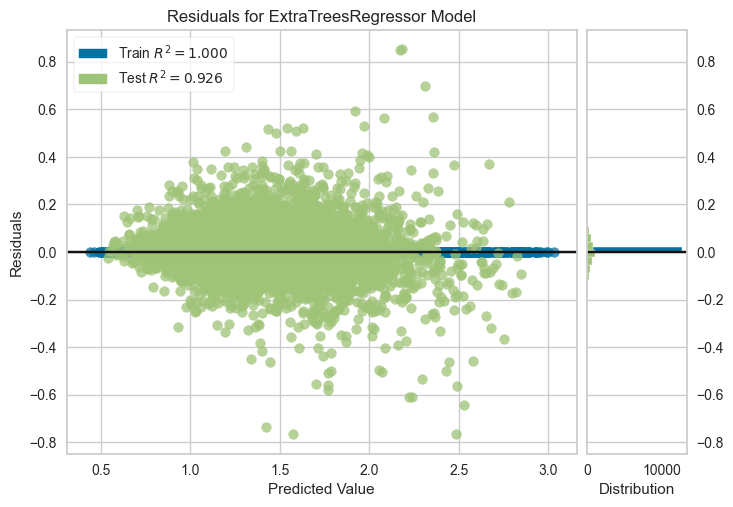

In [57]:
# Create Extra Trees Regressor
best_model = create_model('et', fold=5)

# Plot Residuals
plot_model(best_model, plot='residuals')

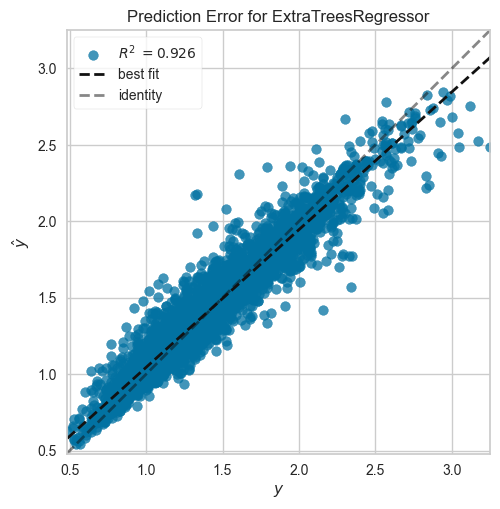

In [59]:
# Plot Error Prediction for Best Model
plot_model(best_model, plot='error')

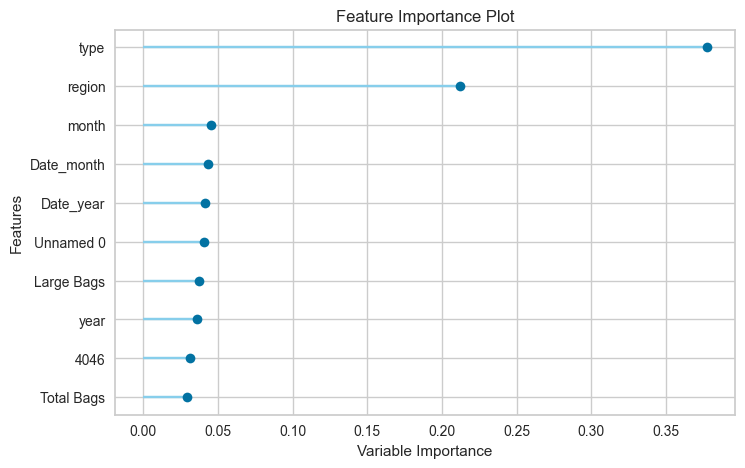

In [61]:
# Plot Feature Importance for Best Model
plot_model(best_model, plot='feature')

In [63]:
# Tuning Best Model
tuned_best = tune_model(best_model, fold=3, n_iter=3, choose_better=True)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.2718,0.1185,0.3443,0.2752,0.1410,0.2134
1,0.2679,0.1146,0.3385,0.2742,0.1395,0.2127
2,0.2695,0.1203,0.3468,0.2641,0.1412,0.2111
Mean,0.2697,0.1178,0.3432,0.2712,0.1406,0.2124
Std,0.0016,0.0024,0.0035,0.0050,0.0008,0.0010


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


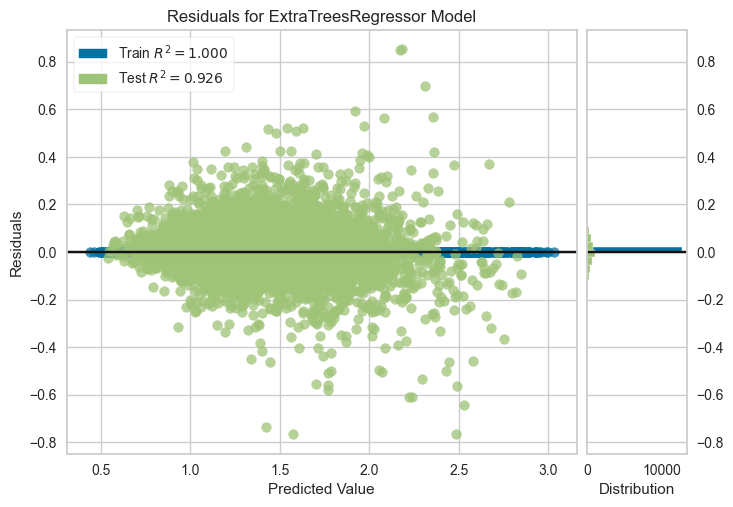

In [64]:
# Plot the Residual of Tuned Best Model
plot_model(tuned_best, plot='residuals')

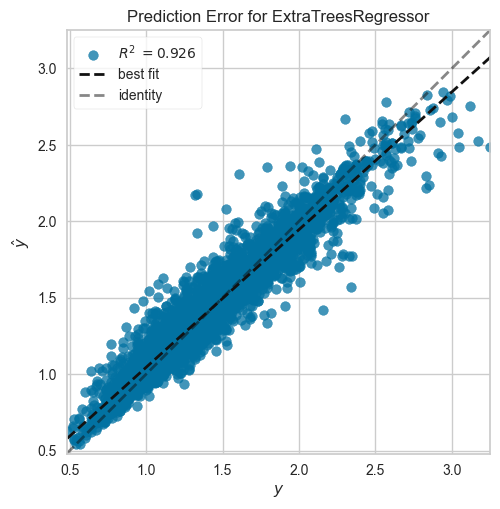

In [65]:
# Plot Error Prediction for Tuned Best Model
plot_model(tuned_best, plot='error')

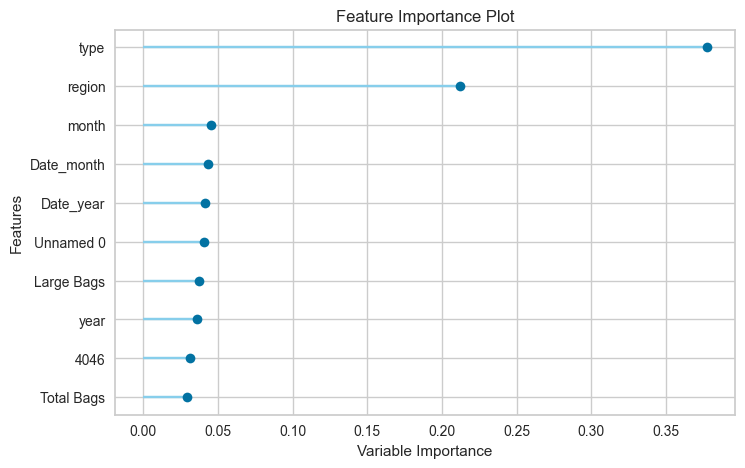

In [66]:
# Plot Feature Importance for Tuned Best Model
plot_model(tuned_best, plot='feature')

In [68]:
# Create RFR Model
rf = create_model('rf', fold=3, n_estimators=30, n_jobs=1)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.0910,0.0161,0.1270,0.9013,0.0512,0.0672
1,0.0899,0.0160,0.1264,0.8988,0.0509,0.0665
2,0.0952,0.0184,0.1357,0.8873,0.0542,0.0704
Mean,0.0920,0.0168,0.1297,0.8958,0.0521,0.0680
Std,0.0023,0.0011,0.0042,0.0061,0.0015,0.0017


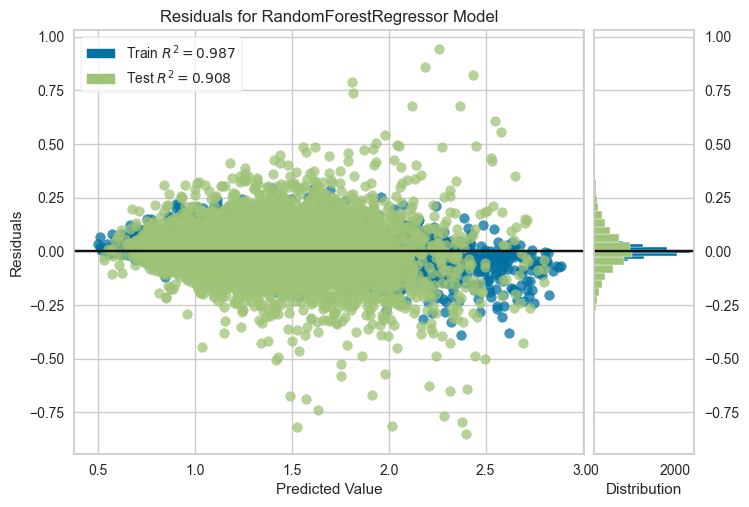

In [69]:
# Plot the Residual of RFR Model
plot_model(rf, plot='residuals')

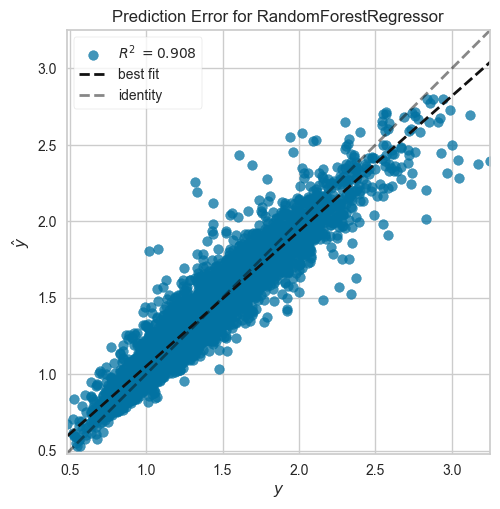

In [70]:
# Plot Error Prediction for RFR Model
plot_model(rf, plot='error')

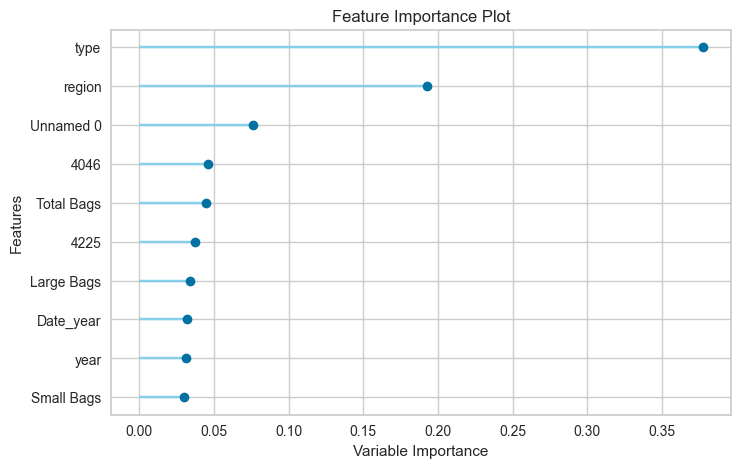

In [71]:
# Plot Feature Importance for RFR Model
plot_model(rf, plot='feature')

In [72]:
# Tuning RFR Model
tune_rf = tune_model(rf, fold=3, n_iter=3, choose_better=True)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.2466,0.1000,0.3162,0.3885,0.1292,0.1912
1,0.2451,0.0987,0.3141,0.3750,0.1290,0.1920
2,0.2479,0.1040,0.3226,0.3635,0.1311,0.1922
Mean,0.2465,0.1009,0.3176,0.3757,0.1298,0.1918
Std,0.0011,0.0023,0.0036,0.0102,0.0010,0.0004


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


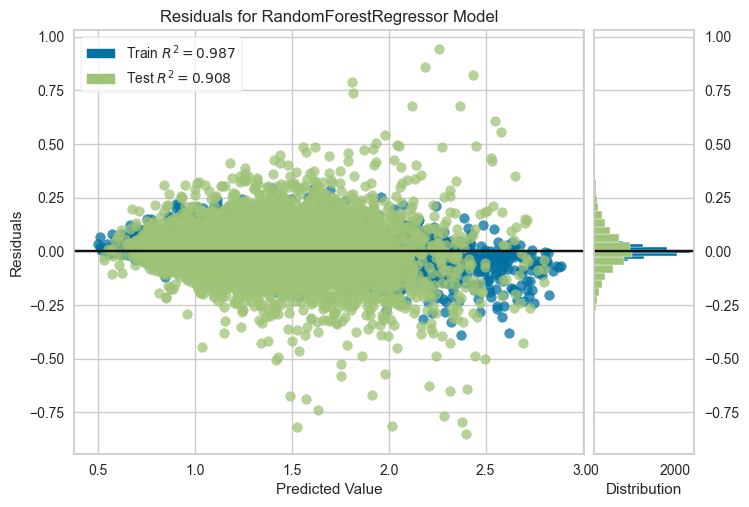

In [73]:
# Plot the Residual of Tuned RFR Model
plot_model(tune_rf, plot='residuals')

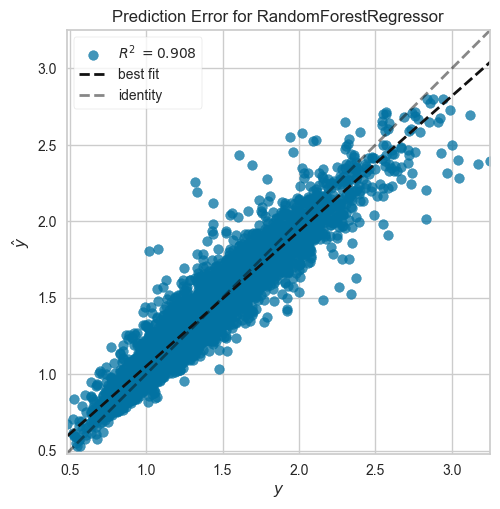

In [74]:
# Plot Error Prediction for Tuned RFR Model
plot_model(tune_rf, plot='error')

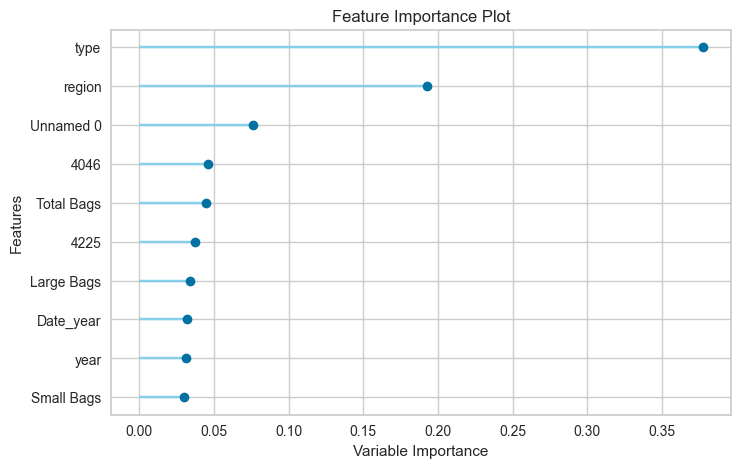

In [75]:
# Plot Feature Importance for Tuned RFR Model
plot_model(tune_rf, plot='feature')

In [76]:
# Create Light GBM
lgbm = create_model('lightgbm', fold=3, n_estimators=30, n_jobs=1, verbosity=-1)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.1284,0.0285,0.1687,0.8259,0.0686,0.0969
1,0.1278,0.0286,0.1691,0.8188,0.0689,0.0969
2,0.1325,0.0314,0.1773,0.8077,0.0721,0.1007
Mean,0.1296,0.0295,0.1717,0.8175,0.0699,0.0982
Std,0.0021,0.0014,0.0039,0.0075,0.0016,0.0018


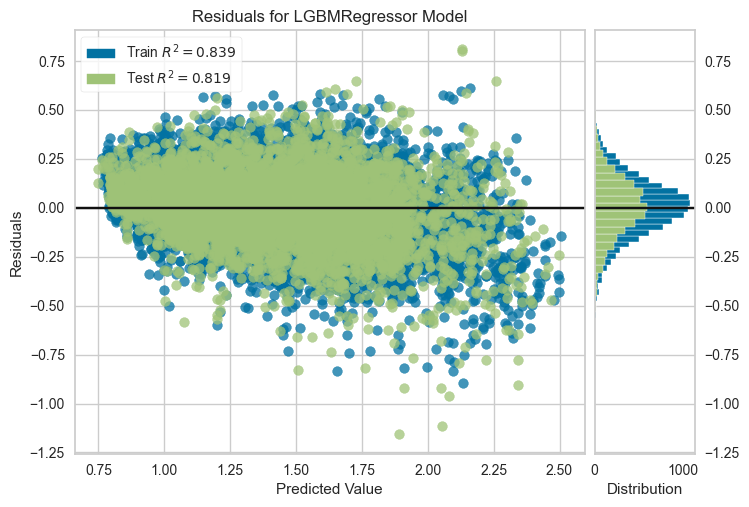

In [77]:
# Plot the Residual of Light GBM
plot_model(lgbm, plot='residuals')

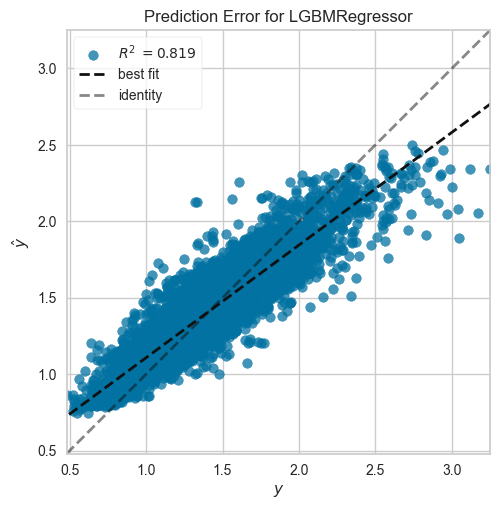

In [78]:
# Plot Error Prediction for Light GBM
plot_model(lgbm, plot='error')

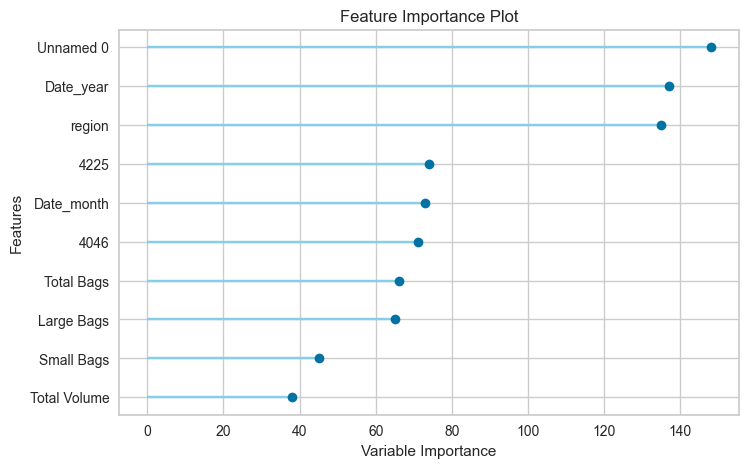

In [79]:
# Plot Feature Importance for Light GBM
plot_model(lgbm, plot='feature')

In [80]:
# Tuning Light Gradient Boost
tune_lgbm = tune_model(lgbm, fold=3, n_iter=3, choose_better=True)

,MAE,MSE,RMSE,R2,RMSLE,MAPE
Fold,,,,,,
0,0.1524,0.0407,0.2017,0.7512,0.0813,0.1142
1,0.1539,0.0411,0.2026,0.7399,0.0821,0.1164
2,0.1595,0.0461,0.2146,0.7183,0.0862,0.1202
Mean,0.1553,0.0426,0.2063,0.7365,0.0832,0.1169
Std,0.0031,0.0024,0.0059,0.0137,0.0021,0.0025


Fitting 3 folds for each of 3 candidates, totalling 9 fits
Original model was better than the tuned model, hence it will be returned. NOTE: The display metrics are for the tuned model (not the original one).


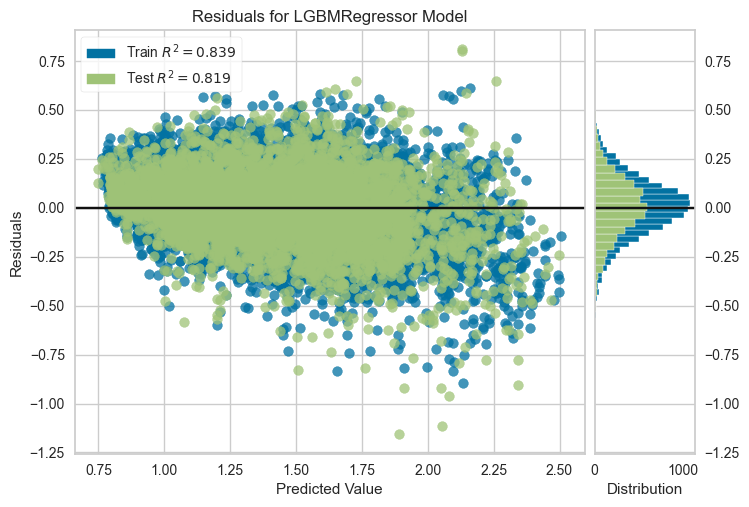

In [81]:
# Plot the Residual of Tuned Light Gradient Boost
plot_model(tune_lgbm, plot='residuals')

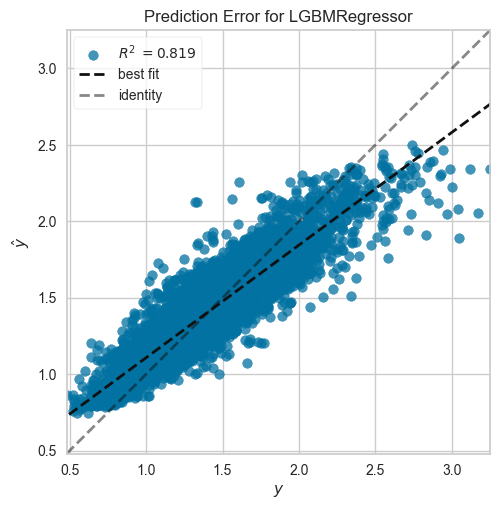

In [82]:
# Plot Error Prediction for Tuned Light Gradient Boost
plot_model(tune_lgbm, plot='error')

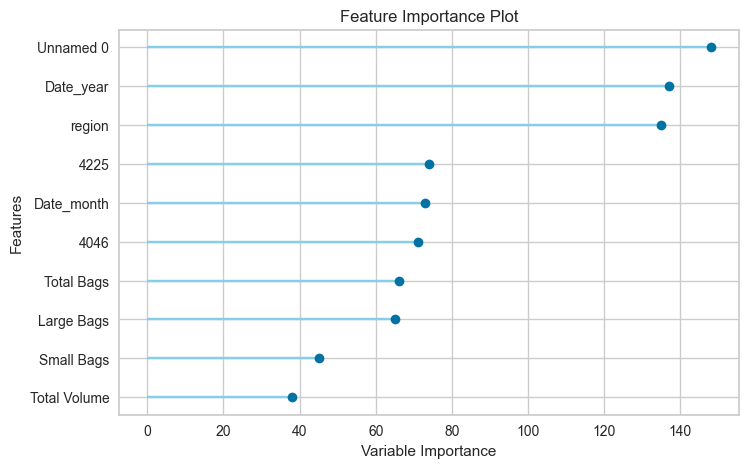

In [83]:
# Plot Feature Importance for Tuned Light Gradient Boost
plot_model(tune_lgbm, plot='feature')

In [84]:
# Prediction using Best Model
predict_model(best_model)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Extra Trees Regressor,0.0743,0.0120,0.1096,0.9265,0.0439,0.0547


,Unnamed: 0,Date,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region,month,AveragePrice,prediction_label
5078,34,2016-05-01,858037.437500,91136.132812,271005.062500,11463.750000,484432.531250,458041.093750,25900.730469,490.709991,conventional,2016,Seattle,5,0.82,0.8579
10697,11,2015-10-11,8749.599609,6.000000,68.349998,0.000000,8675.250000,8675.250000,0.000000,0.000000,organic,2015,NorthernNewEngland,10,1.61,1.6228
15569,33,2017-05-14,143791.203125,3379.520020,73032.429688,0.000000,67379.257812,29130.710938,38248.550781,0.000000,organic,2017,GreatLakes,5,1.68,1.5663
2001,25,2015-07-05,287571.937500,94880.312500,118022.578125,15212.240234,59456.820312,58905.710938,551.109985,0.000000,conventional,2015,RichmondNorfolk,7,1.01,1.0351
15780,32,2017-05-21,8759.490234,76.820000,1259.859985,0.000000,7422.810059,2038.260010,5384.549805,0.000000,organic,2017,Indianapolis,5,0.92,1.4358
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9571,29,2015-06-07,19636.240234,857.739990,18325.169922,0.000000,453.329987,453.329987,0.000000,0.000000,organic,2015,Chicago,6,1.85,1.7597
13448,7,2016-11-06,89099.078125,5608.509766,26861.460938,140.679993,56488.429688,55962.011719,526.419983,0.000000,organic,2016,Northeast,11,2.07,1.9910
17719,10,2018-01-14,19434.359375,610.289978,5917.680176,0.000000,12906.389648,4369.520020,8536.870117,0.000000,organic,2018,CincinnatiDayton,1,1.71,1.5624
10243,25,2015-07-05,10492.769531,4751.990234,5225.479980,0.000000,515.299988,235.160004,280.140015,0.000000,organic,2015,LasVegas,7,1.60,1.7492


In [85]:
# Prediction using RFR Model
predict_model(rf)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Random Forest Regressor,0.0844,0.0150,0.1226,0.9080,0.0483,0.0615


,Unnamed: 0,Date,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region,month,AveragePrice,prediction_label
5078,34,2016-05-01,858037.437500,91136.132812,271005.062500,11463.750000,484432.531250,458041.093750,25900.730469,490.709991,conventional,2016,Seattle,5,0.82,0.848333
10697,11,2015-10-11,8749.599609,6.000000,68.349998,0.000000,8675.250000,8675.250000,0.000000,0.000000,organic,2015,NorthernNewEngland,10,1.61,1.621000
15569,33,2017-05-14,143791.203125,3379.520020,73032.429688,0.000000,67379.257812,29130.710938,38248.550781,0.000000,organic,2017,GreatLakes,5,1.68,1.526667
2001,25,2015-07-05,287571.937500,94880.312500,118022.578125,15212.240234,59456.820312,58905.710938,551.109985,0.000000,conventional,2015,RichmondNorfolk,7,1.01,1.045000
15780,32,2017-05-21,8759.490234,76.820000,1259.859985,0.000000,7422.810059,2038.260010,5384.549805,0.000000,organic,2017,Indianapolis,5,0.92,1.272333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9571,29,2015-06-07,19636.240234,857.739990,18325.169922,0.000000,453.329987,453.329987,0.000000,0.000000,organic,2015,Chicago,6,1.85,1.703333
13448,7,2016-11-06,89099.078125,5608.509766,26861.460938,140.679993,56488.429688,55962.011719,526.419983,0.000000,organic,2016,Northeast,11,2.07,1.875000
17719,10,2018-01-14,19434.359375,610.289978,5917.680176,0.000000,12906.389648,4369.520020,8536.870117,0.000000,organic,2018,CincinnatiDayton,1,1.71,1.558000
10243,25,2015-07-05,10492.769531,4751.990234,5225.479980,0.000000,515.299988,235.160004,280.140015,0.000000,organic,2015,LasVegas,7,1.60,1.643333


In [86]:
# Prediction using Light Gradient Boosting Model
predict_model(lgbm)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Light Gradient Boosting Machine,0.1288,0.0296,0.1721,0.8187,0.0689,0.0959


,Unnamed: 0,Date,Total Volume,4046,4225,4770,Total Bags,Small Bags,Large Bags,XLarge Bags,type,year,region,month,AveragePrice,prediction_label
5078,34,2016-05-01,858037.437500,91136.132812,271005.062500,11463.750000,484432.531250,458041.093750,25900.730469,490.709991,conventional,2016,Seattle,5,0.82,1.019315
10697,11,2015-10-11,8749.599609,6.000000,68.349998,0.000000,8675.250000,8675.250000,0.000000,0.000000,organic,2015,NorthernNewEngland,10,1.61,1.505773
15569,33,2017-05-14,143791.203125,3379.520020,73032.429688,0.000000,67379.257812,29130.710938,38248.550781,0.000000,organic,2017,GreatLakes,5,1.68,1.448413
2001,25,2015-07-05,287571.937500,94880.312500,118022.578125,15212.240234,59456.820312,58905.710938,551.109985,0.000000,conventional,2015,RichmondNorfolk,7,1.01,1.053768
15780,32,2017-05-21,8759.490234,76.820000,1259.859985,0.000000,7422.810059,2038.260010,5384.549805,0.000000,organic,2017,Indianapolis,5,0.92,1.367525
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9571,29,2015-06-07,19636.240234,857.739990,18325.169922,0.000000,453.329987,453.329987,0.000000,0.000000,organic,2015,Chicago,6,1.85,1.759249
13448,7,2016-11-06,89099.078125,5608.509766,26861.460938,140.679993,56488.429688,55962.011719,526.419983,0.000000,organic,2016,Northeast,11,2.07,1.886975
17719,10,2018-01-14,19434.359375,610.289978,5917.680176,0.000000,12906.389648,4369.520020,8536.870117,0.000000,organic,2018,CincinnatiDayton,1,1.71,1.458446
10243,25,2015-07-05,10492.769531,4751.990234,5225.479980,0.000000,515.299988,235.160004,280.140015,0.000000,organic,2015,LasVegas,7,1.60,1.746259


In [87]:
# Finalize Best Model
final_best = finalize_model(best_model)

# Final Best Model Parameters for Deployment
print(final_best)
print(final_best.get_params())

Pipeline(memory=Memory(location=None),
         steps=[('date_feature_extractor',
                 TransformerWrapper(include=['Date'],
                                    transformer=ExtractDateTimeFeatures())),
                ('numerical_imputer',
                 TransformerWrapper(include=['Unnamed: 0', 'Total Volume',
                                             '4046', '4225', '4770',
                                             'Total Bags', 'Small Bags',
                                             'Large Bags', 'XLarge Bags',
                                             'year', 'month'],
                                    transformer=SimpleImputer())),
                ('categorica...
                                                               mapping=[{'col': 'type',
                                                                         'data_type': dtype('O'),
                                                                         'mapping': conventional    0
organic 

In [88]:
# Prediction using Final Model
predict_model(final_best)

,Model,MAE,MSE,RMSE,R2,RMSLE,MAPE
0,Extra Trees Regressor,0.0381,0.0044,0.0660,0.9733,0.0264,0.0276


,Unnamed: 0,Date,Total Volume,4046,4225,...,year,region,month,AveragePrice,prediction_label
5078,34,2016-05-01,858037.437500,91136.132812,271005.062500,...,2016,Seattle,5,0.82,0.9172
10697,11,2015-10-11,8749.599609,6.000000,68.349998,...,2015,NorthernNewEngland,10,1.61,1.5695
15569,33,2017-05-14,143791.203125,3379.520020,73032.429688,...,2017,GreatLakes,5,1.68,1.6135
2001,25,2015-07-05,287571.937500,94880.312500,118022.578125,...,2015,RichmondNorfolk,7,1.01,1.0069
15780,32,2017-05-21,8759.490234,76.820000,1259.859985,...,2017,Indianapolis,5,0.92,0.9844
...,...,...,...,...,...,...,...,...,...,...,...
9571,29,2015-06-07,19636.240234,857.739990,18325.169922,...,2015,Chicago,6,1.85,1.8164
13448,7,2016-11-06,89099.078125,5608.509766,26861.460938,...,2016,Northeast,11,2.07,2.0362
17719,10,2018-01-14,19434.359375,610.289978,5917.680176,...,2018,CincinnatiDayton,1,1.71,1.6847
10243,25,2015-07-05,10492.769531,4751.990234,5225.479980,...,2015,LasVegas,7,1.60,1.6099


In [89]:
# Save Final Model into Pickle File
save_model(final_best, 'Final_Best_Model_Avocado')

Transformation Pipeline and Model Successfully Saved


(Pipeline(memory=Memory(location=None),
          steps=[('date_feature_extractor',
                  TransformerWrapper(include=['Date'],
                                     transformer=ExtractDateTimeFeatures())),
                 ('numerical_imputer',
                  TransformerWrapper(include=['Unnamed: 0', 'Total Volume',
                                              '4046', '4225', '4770',
                                              'Total Bags', 'Small Bags',
                                              'Large Bags', 'XLarge Bags',
                                              'year', 'month'],
                                     transformer=SimpleImputer())),
                 ('categorica...
                                                                mapping=[{'col': 'type',
                                                                          'data_type': dtype('O'),
                                                                          'mapping': conventiona